/opt/homebrew/opt/python@3.11/bin/python3.11


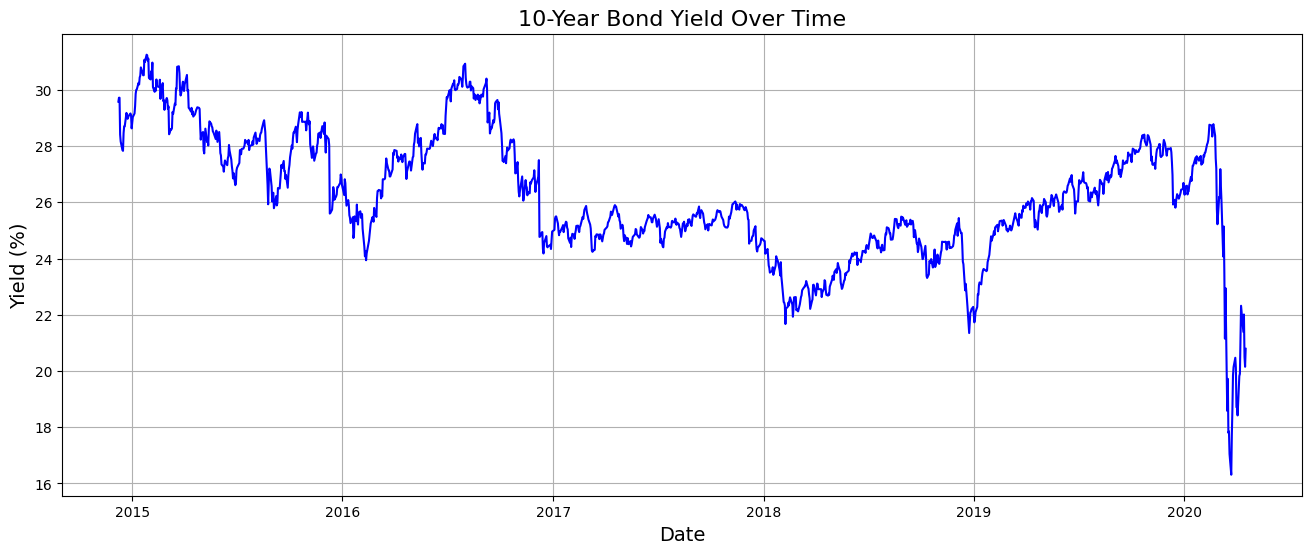

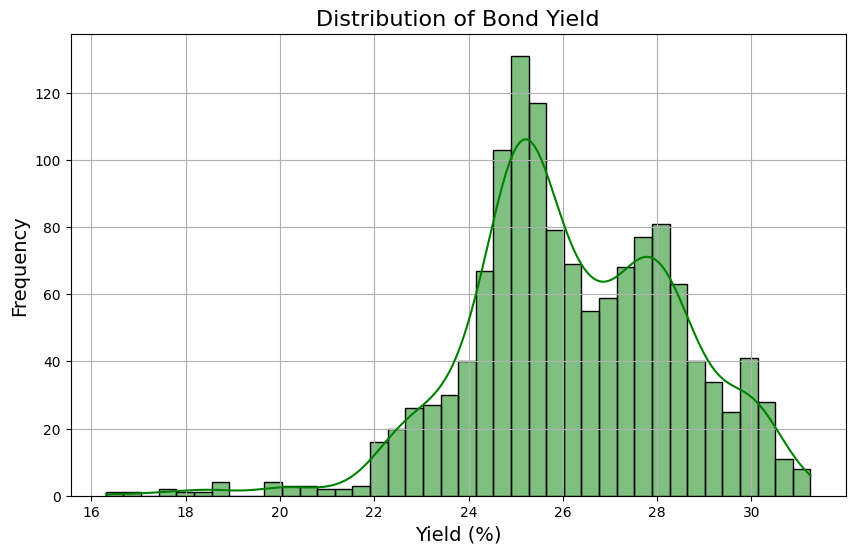

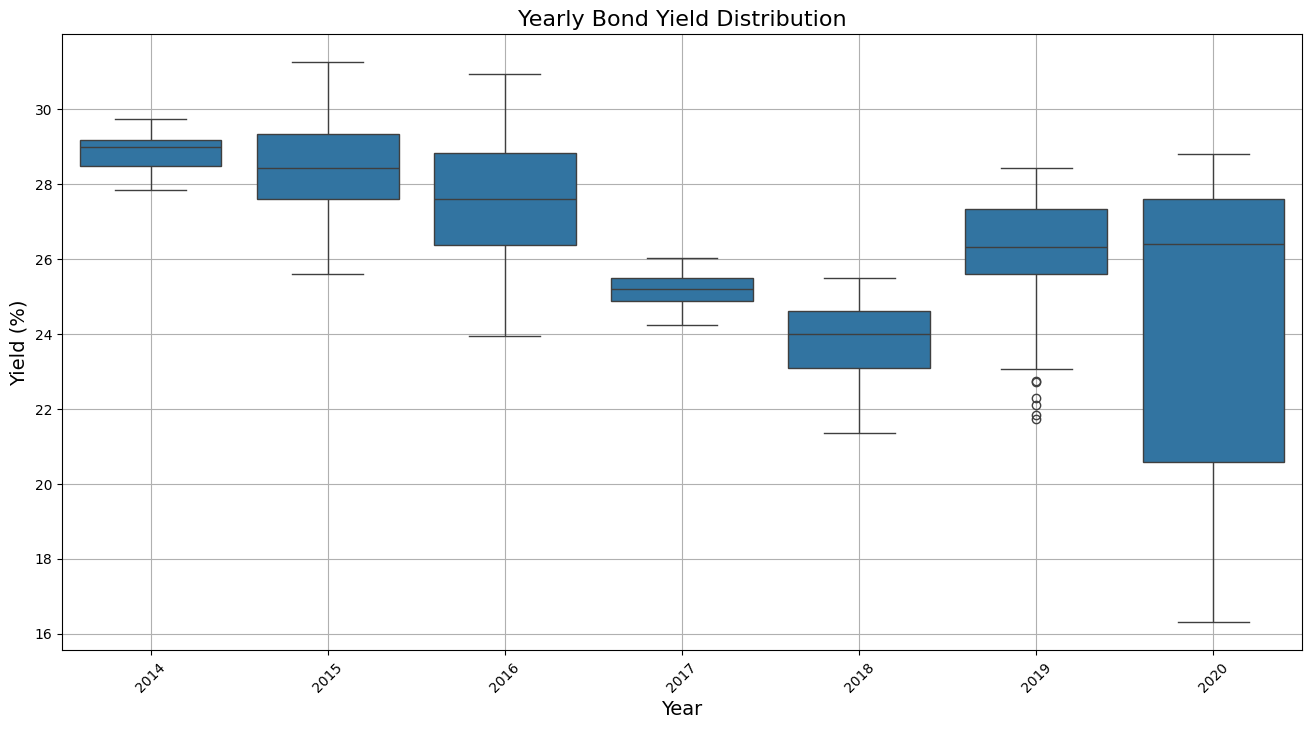

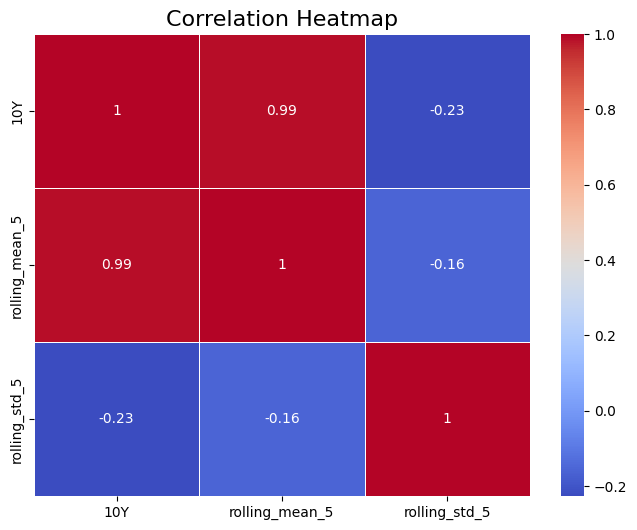

In [14]:
import sys
print(sys.executable)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv('india_bond_yields_2010_2025.csv', parse_dates=['Date'])
# Remove rows where 'yield' column has non-numeric entries
data = data[pd.to_numeric(data['10Y'], errors='coerce').notnull()]

# Convert yield to numeric explicitly
data['10Y'] = data['10Y'].astype(float)
# Yield over Time
plt.figure(figsize=(16, 6))
plt.plot(data['Date'], data['10Y'], color='blue', linewidth=1.5)
plt.title('10-Year Bond Yield Over Time', fontsize=16)
plt.xlabel('Date', fontsize=14)
plt.ylabel('Yield (%)', fontsize=14)
plt.grid(True)
plt.show()

# Yield Distribution
plt.figure(figsize=(10, 6))
sns.histplot(data['10Y'], kde=True, bins=40, color='green')
plt.title('Distribution of Bond Yield', fontsize=16)
plt.xlabel('Yield (%)', fontsize=14)
plt.ylabel('Frequency', fontsize=14)
plt.grid(True)
plt.show()

# Box Plot (Yearly)
data['year'] = data['Date'].dt.year
plt.figure(figsize=(16, 8))
sns.boxplot(x='year', y='10Y', data=data)
plt.title('Yearly Bond Yield Distribution', fontsize=16)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Yield (%)', fontsize=14)
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

# Rolling mean and std (Correlation Heatmap)
data['rolling_mean_5'] = data['10Y'].rolling(window=5).mean()
data['rolling_std_5'] = data['10Y'].rolling(window=5).std()

plt.figure(figsize=(8, 6))
sns.heatmap(data[['10Y', 'rolling_mean_5', 'rolling_std_5']].corr(), annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap', fontsize=16)
plt.show()

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv('india_bond_yields_2010_2025.csv', parse_dates=['Date'],index_col='Date')
print(data)
# Remove rows where 'yield' column has non-numeric entries
data = data[pd.to_numeric(data['1Y'], errors='coerce').notnull()]

# Convert yield to numeric explicitly
data['1Y'] = data['1Y'].astype(float)

# Remove rows where 'yield' column has non-numeric entries
data = data[pd.to_numeric(data['5Y'], errors='coerce').notnull()]

# Convert yield to numeric explicitly
data['5Y'] = data['5Y'].astype(float)

# Remove rows where 'yield' column has non-numeric entries
data = data[pd.to_numeric(data['10Y'], errors='coerce').notnull()]

# Convert yield to numeric explicitly
data['10Y'] = data['10Y'].astype(float)
# Remove rows where 'yield' column has non-numeric entries
data = data[pd.to_numeric(data['10Y'], errors='coerce').notnull()]

# Convert yield to numeric explicitly
data['30Y'] = data['30Y'].astype(float)
data = data[pd.to_numeric(data['30Y'], errors='coerce').notnull()]

data.dropna(inplace=True)

# Yield Curve Slope (10yr - 3mo)
data['Yield_Curve_Slope'] = data['10Y'] - data['1Y']
print(data['Yield_Curve_Slope'])
# Curvature: (2 * 10yr) - (3mo + 30yr)
data['Yield_Curvature'] = (2 * data['10Y']) - (data['1Y'] + data['30Y'])

# Level shift (daily parallel shift across yields)
data['Level_Shift'] = data[['10Y', '1Y', '30Y', '5Y']].mean(axis=1).diff()

# Roll-down (10yr yield changes day-to-day)
data['Roll_Down'] = data['10Y'].diff()

# Duration (simplified approximation using Modified Duration concept)
data['Duration'] = -data['10Y'].pct_change() / 0.01  # change per 1% yield shift

# Convexity (approximation)
data['Convexity'] = data['Duration'].diff()

# Term spreads
data['30y_5y_Spread'] = data['30Y'] - data['5Y']
data['10y_1y_Spread'] = data['10Y'] - data['1Y']

# Nelson-Siegel Model Simplified factors
data['NS_Level'] = data[['1Y', '5Y', '10Y', '30Y']].mean(axis=1)
data['NS_Slope'] = data['10Y'] - data['1Y']
data['NS_Curvature'] = data['5Y'] - ((data['1Y'] + data['10Y']) / 2)

# Clean data (drop NaN from diff calculations)
data.dropna(inplace=True)

# Save for modeling
data.to_csv('bond_yield_technical_indicators.csv')

print(data.head())

               1Y     5Y    10Y    30Y
Date                                  
2014-12-08  29.45  10.91  29.58  28.94
2014-12-09  29.59  10.92  29.72  29.07
2014-12-10  29.59  10.82  29.72  29.07
2014-12-11  28.30  10.83  28.41  27.82
2014-12-12  28.05  10.74  28.16  27.57
...           ...    ...    ...    ...
2024-12-27    NaN  11.08    NaN    NaN
2024-12-30    NaN  11.03    NaN    NaN
2024-12-31    NaN  11.01    NaN    NaN
2025-01-02    NaN  11.01    NaN    NaN
2025-01-03    NaN  11.08    NaN    NaN

[2528 rows x 4 columns]
Date
2014-12-08    0.13
2014-12-09    0.13
2014-12-10    0.13
2014-12-11    0.11
2014-12-12    0.11
              ... 
2020-04-13    0.13
2020-04-14    0.14
2020-04-15    0.13
2020-04-16    0.13
2020-04-17    0.13
Name: Yield_Curve_Slope, Length: 1340, dtype: float64
               1Y     5Y    10Y    30Y  Yield_Curve_Slope  Yield_Curvature  \
Date                                                                         
2014-12-10  29.59  10.82  29.72  29.07      

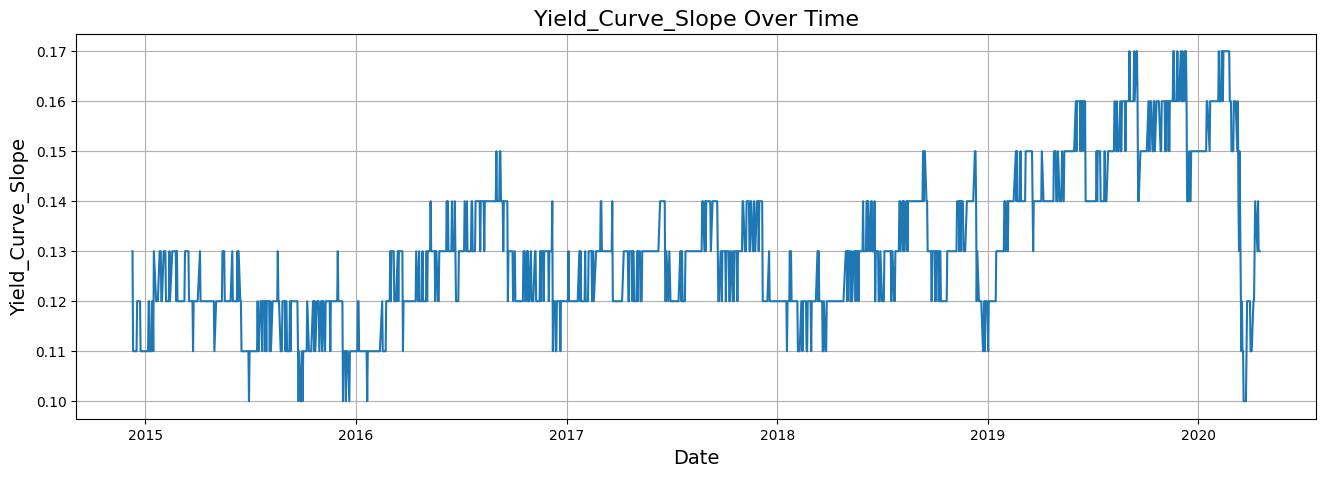

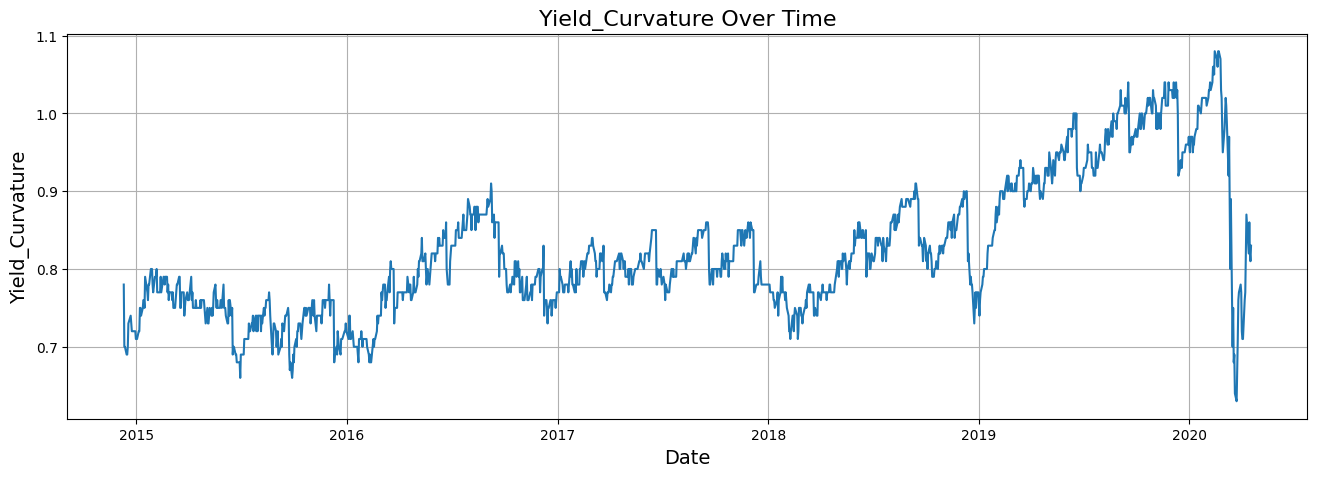

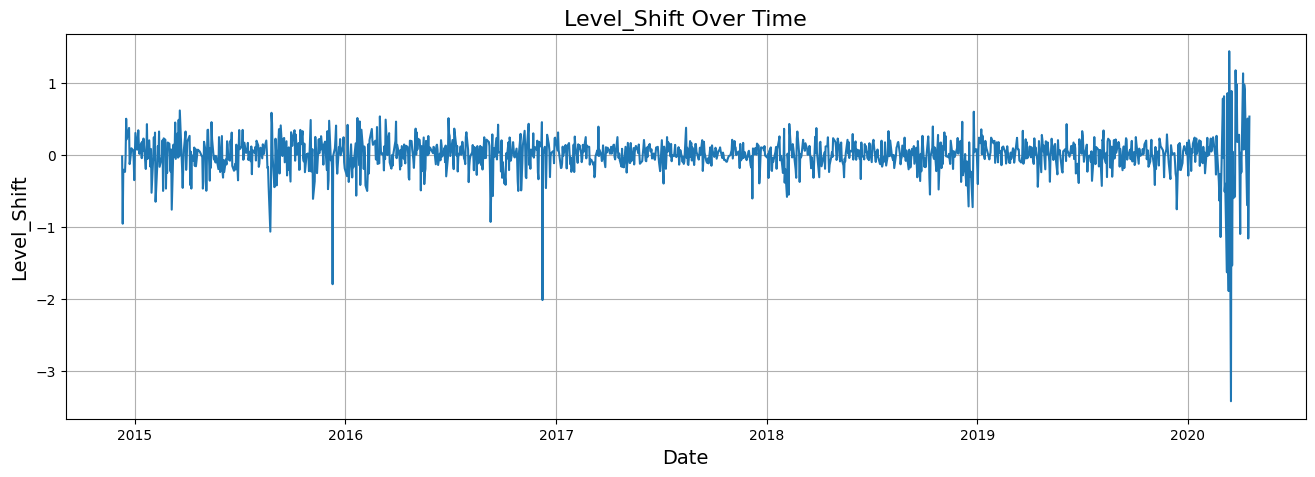

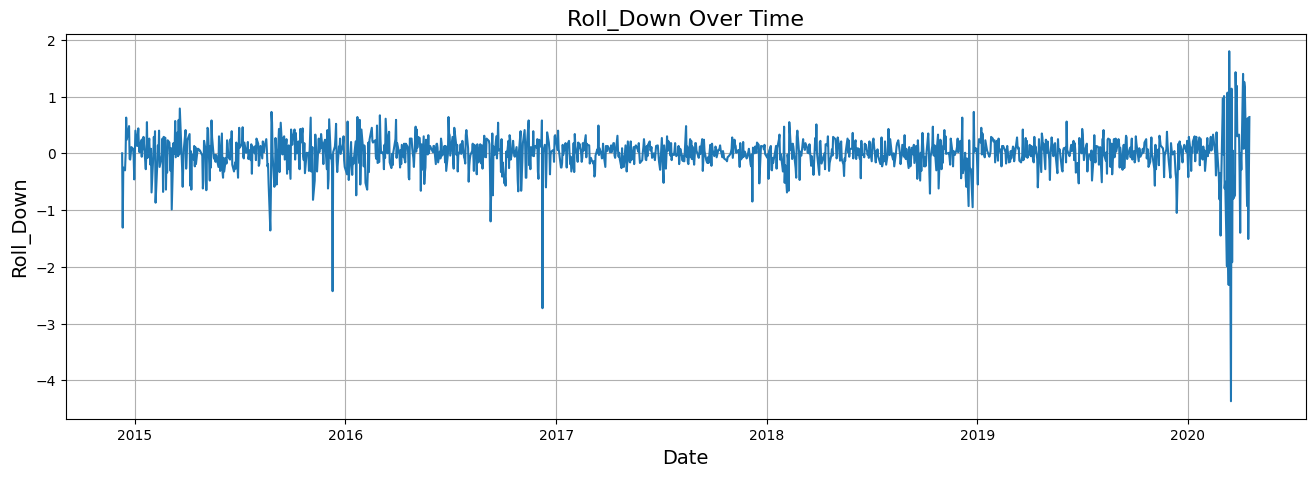

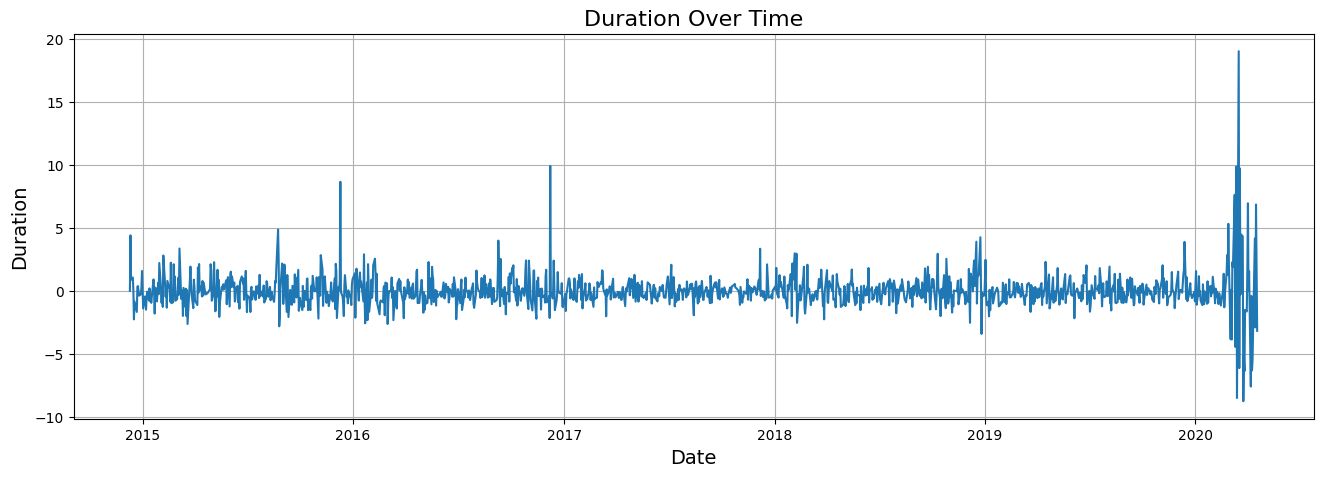

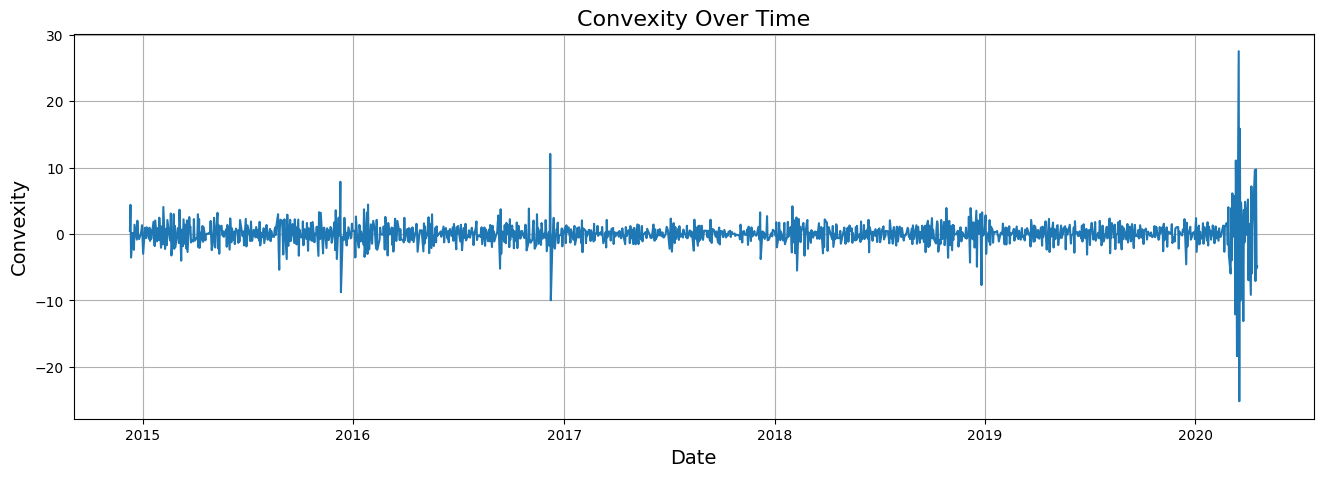

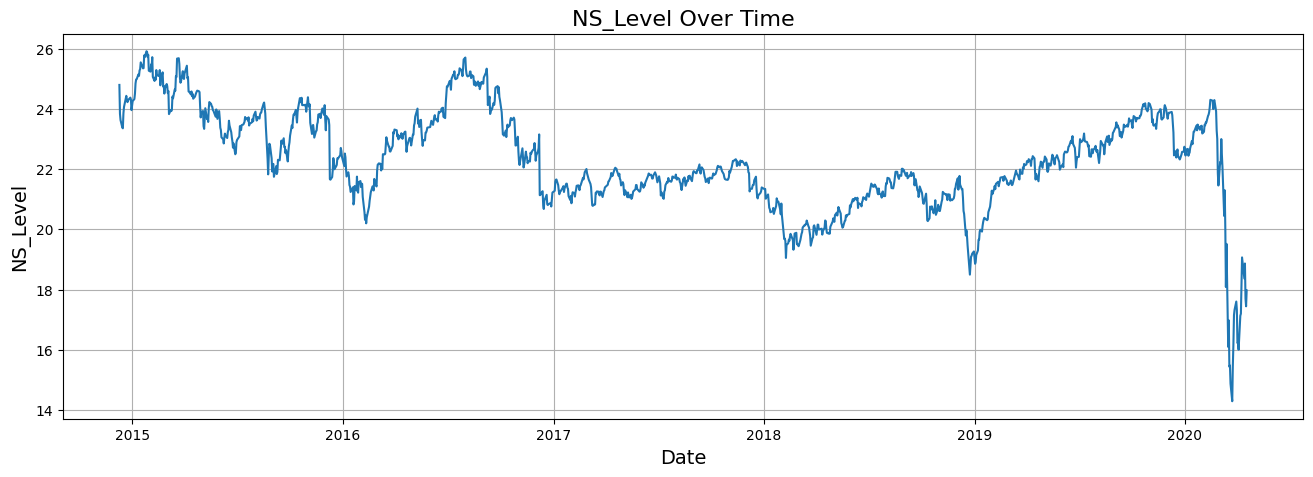

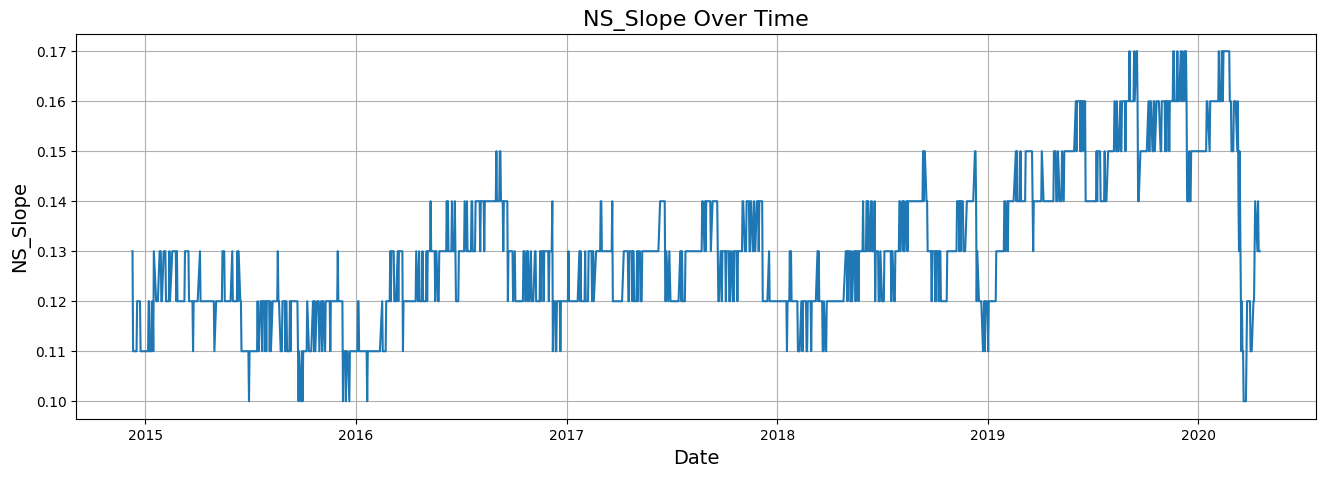

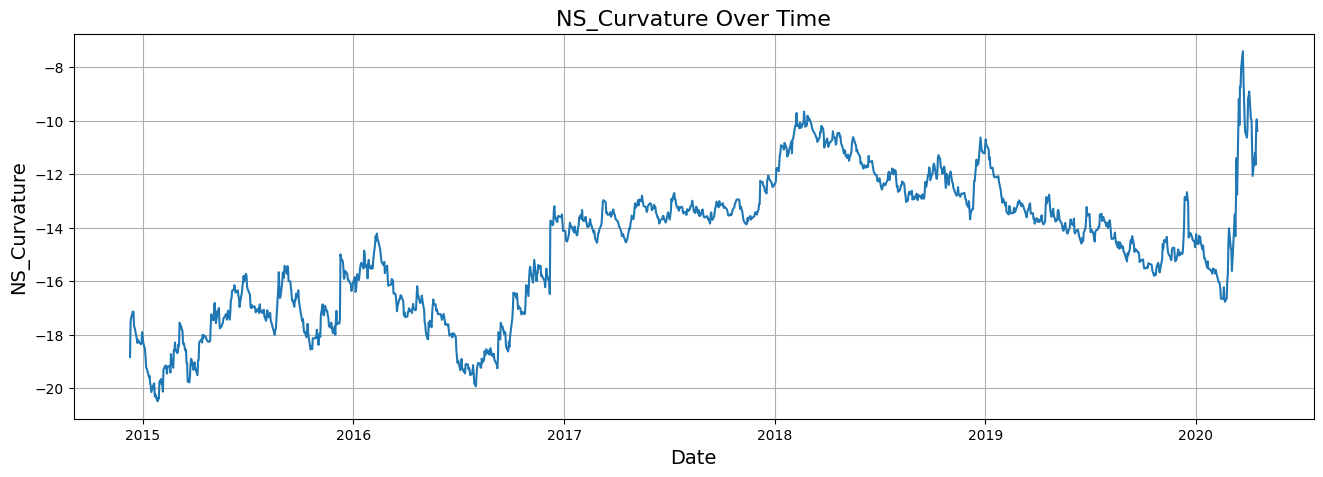

In [16]:
import matplotlib.pyplot as plt

data = pd.read_csv('bond_yield_technical_indicators.csv', parse_dates=['Date'])

indicators = ['Yield_Curve_Slope', 'Yield_Curvature', 'Level_Shift', 
              'Roll_Down', 'Duration', 'Convexity', 'NS_Level', 'NS_Slope', 'NS_Curvature']

for indicator in indicators:
    plt.figure(figsize=(16,5))
    plt.plot(data['Date'], data[indicator])
    plt.title(f'{indicator} Over Time', fontsize=16)
    plt.xlabel('Date', fontsize=14)
    plt.ylabel(indicator, fontsize=14)
    plt.grid(True)
    plt.show()

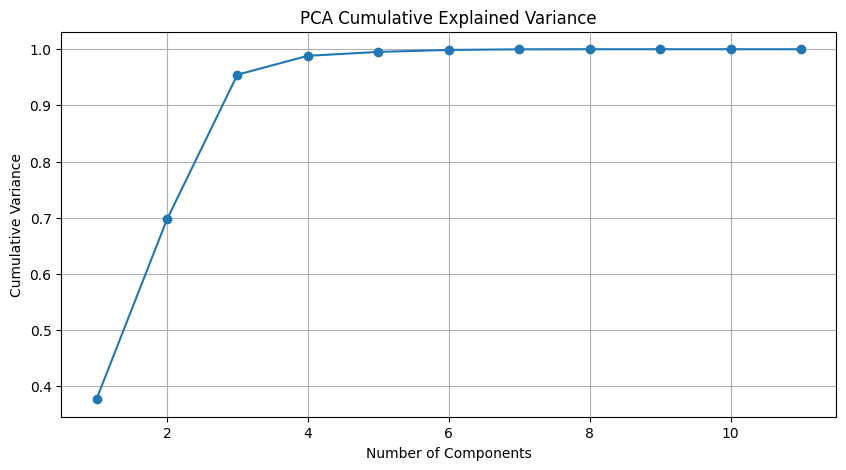

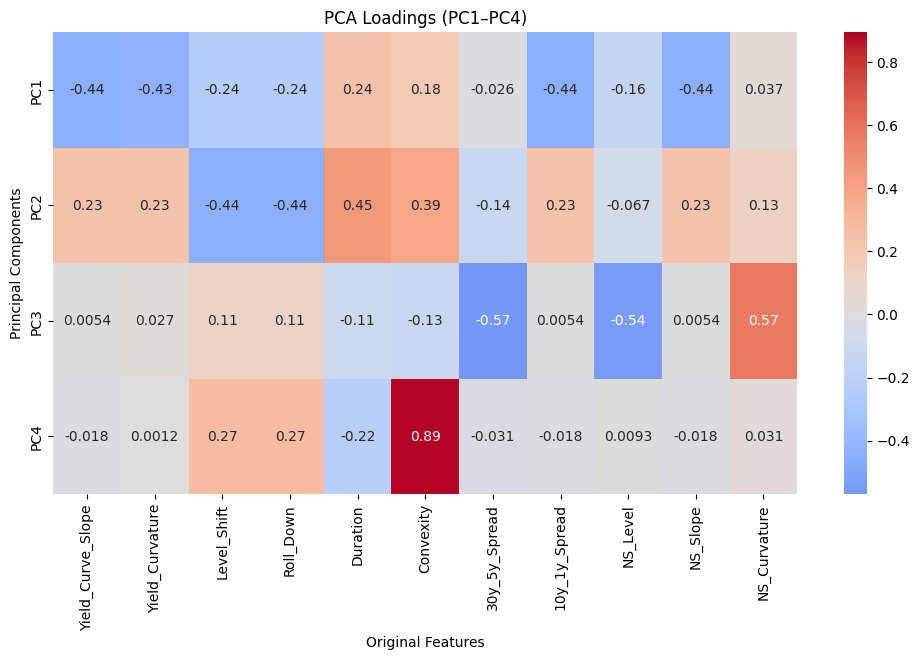

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1) Load your engineered dataset
df = pd.read_csv('bond_yield_technical_indicators.csv')

# 2) Select and standardize the feature matrix
features = [
    'Yield_Curve_Slope','Yield_Curvature','Level_Shift','Roll_Down',
    'Duration','Convexity','30y_5y_Spread','10y_1y_Spread',
    'NS_Level','NS_Slope','NS_Curvature'
]
X = df[features].values
X_centered = X - X.mean(axis=0)
X_std = X_centered / X.std(axis=0)

# 3) Compute covariance matrix and its eigen-decomposition
cov = np.cov(X_std, rowvar=False)
eigs, vecs = np.linalg.eigh(cov)

# 4) Sort eigenvalues/vectors descending
idx = np.argsort(eigs)[::-1]
eigs_sorted = eigs[idx]
vecs_sorted = vecs[:, idx]

# 5) Explained-variance ratio & cumulative plot
explained = eigs_sorted / eigs_sorted.sum()
cum_explained = np.cumsum(explained)

plt.figure(figsize=(10,5))
plt.plot(np.arange(1, len(explained)+1), cum_explained, 'o-')
plt.title('PCA Cumulative Explained Variance')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Variance')
plt.grid(True)
plt.show()

# 6) Loadings heatmap (first few PCs)
loadings = pd.DataFrame(vecs_sorted.T, 
                        columns=features, 
                        index=[f'PC{i+1}' for i in range(len(features))])

plt.figure(figsize=(12,6))
sns.heatmap(loadings.iloc[:4], annot=True, cmap='coolwarm', center=0)
plt.title('PCA Loadings (PC1–PC4)')
plt.xlabel('Original Features')
plt.ylabel('Principal Components')
plt.show()

In [18]:
X_std     # your (n×11) standardized feature matrix
eigs_sorted, vecs_sorted  # from your manual PCA via np.linalg.eigh()

(array([4.14834188e+00, 3.52336071e+00, 2.83770633e+00, 3.69993965e-01,
        7.60678178e-02, 3.85613218e-02, 1.22481471e-02, 1.94720991e-03,
        1.04865065e-14, 6.66676129e-16, 1.32600939e-16]),
 array([[-4.40416910e-01,  2.32948030e-01,  5.41631471e-03,
         -1.76778826e-02,  1.96344931e-01, -2.14865257e-01,
          3.84615959e-03, -4.72937107e-03, -4.21296520e-01,
         -4.17637785e-03, -6.99401563e-01],
        [-4.30987115e-01,  2.34088599e-01,  2.66894717e-02,
          1.20216236e-03, -3.96017243e-01,  7.75063907e-01,
         -2.24163576e-02,  8.79760654e-03, -6.24772035e-05,
          2.46018019e-02, -3.82250735e-05],
        [-2.39728634e-01, -4.44938736e-01,  1.10393861e-01,
          2.71871329e-01, -1.10623668e-02, -1.21262425e-02,
         -3.93517165e-01, -7.09460146e-01, -2.48162864e-14,
          3.68710753e-14, -5.49394365e-15],
        [-2.41097006e-01, -4.44078185e-01,  1.10212704e-01,
          2.71854891e-01,  1.43240042e-02, -1.64726818e-02,
      

1338
           PC1       PC2       PC3       Date
0    -0.081447 -0.555183 -2.760115 2014-12-10
1     5.088029  3.753054 -3.297530 2014-12-11
2     2.444639 -1.360187 -1.746475 2014-12-12
3     2.928503 -0.509012 -1.835542 2014-12-15
4     2.301299 -1.704292 -1.512118 2014-12-16
...        ...       ...       ...        ...
1333  3.267066  5.902983  1.392344 2020-04-13
1334 -2.652862 -2.782995  3.623584 2020-04-14
1335  4.632783  8.396522  1.424190 2020-04-15
1336  0.976308  1.118086  3.725820 2020-04-16
1337 -1.371291 -2.940765  4.378666 2020-04-17

[1338 rows x 4 columns]
           Date     1Y     5Y    10Y    30Y  Yield_Curve_Slope  \
0    2014-12-10  29.59  10.82  29.72  29.07               0.13   
1    2014-12-11  28.30  10.83  28.41  27.82               0.11   
2    2014-12-12  28.05  10.74  28.16  27.57               0.11   
3    2014-12-15  27.75  10.67  27.86  27.28               0.11   
4    2014-12-16  27.72  10.63  27.83  27.25               0.11   
...         ...    ...

/opt/homebrew/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


60/60 - 2s - 38ms/step - loss: 480.8157 - val_loss: 73.8272
Epoch 2/50
60/60 - 0s - 3ms/step - loss: 54.2672 - val_loss: 50.3822
Epoch 3/50
60/60 - 0s - 3ms/step - loss: 9.8697 - val_loss: 8.1950
Epoch 4/50
60/60 - 0s - 3ms/step - loss: 3.3577 - val_loss: 1.1824
Epoch 5/50
60/60 - 0s - 3ms/step - loss: 1.2400 - val_loss: 0.9887
Epoch 6/50
60/60 - 0s - 3ms/step - loss: 0.6769 - val_loss: 0.4452
Epoch 7/50
60/60 - 0s - 3ms/step - loss: 0.5062 - val_loss: 0.3400
Epoch 8/50
60/60 - 0s - 3ms/step - loss: 0.3648 - val_loss: 0.6810
Epoch 9/50
60/60 - 0s - 3ms/step - loss: 0.3043 - val_loss: 0.3621
Epoch 10/50
60/60 - 0s - 3ms/step - loss: 0.2529 - val_loss: 0.5061
Epoch 11/50
60/60 - 0s - 3ms/step - loss: 0.2334 - val_loss: 0.3368
Epoch 12/50
60/60 - 0s - 3ms/step - loss: 0.2144 - val_loss: 0.3373
Epoch 13/50
60/60 - 0s - 3ms/step - loss: 0.2162 - val_loss: 0.2099
Epoch 14/50
60/60 - 0s - 3ms/step - loss: 0.1998 - val_loss: 0.2900
Epoch 15/50
60/60 - 0s - 3ms/step - loss: 0.1648 - val_loss: 0

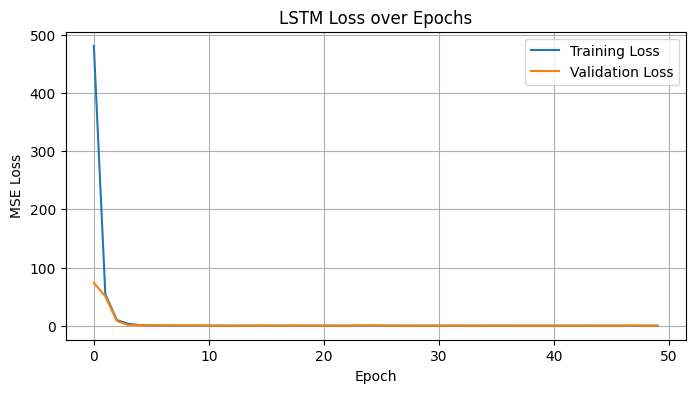

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step


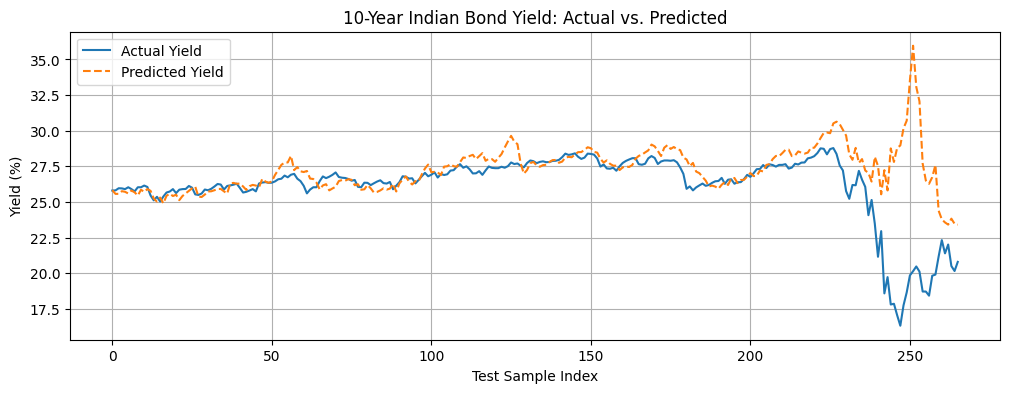

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# 1) Load your technical indicators
tech_df = pd.read_csv('bond_yield_technical_indicators.csv', parse_dates=['Date'])
features = [
    'Yield_Curve_Slope','Yield_Curvature','Level_Shift','Roll_Down',
    'Duration','Convexity','30y_5y_Spread','10y_1y_Spread',
    'NS_Level','NS_Slope','NS_Curvature'
]
print(len(tech_df))
# 2) Standardize the features (zero mean, unit variance)
X = tech_df[features].values
X_mean = X.mean(axis=0)
X_stdv = X.std(axis=0)
X_std = (X - X_mean) / X_stdv  # shape (n_samples, 11)

# 3) Manual PCA via covariance & eigen‐decomposition
cov = np.cov(X_std, rowvar=False)            # 11×11 covariance matrix
eigs, vecs = np.linalg.eigh(cov)             # eigs ascending
idx = np.argsort(eigs)[::-1]                 # sort descending
eigs_sorted = eigs[idx]
vecs_sorted = vecs[:, idx]

# 4) Keep top 3 PCs
n_pcs = 3
top_vecs = vecs_sorted[:, :n_pcs]            # 11×3
PCs = X_std.dot(top_vecs)                    # n_samples×3

# 5) Build a DataFrame of PCs and align yields by date
pc_df = pd.DataFrame(PCs, columns=[f'PC{i+1}' for i in range(n_pcs)])
pc_df['Date'] = tech_df['Date']
print(pc_df)
print(tech_df)
data = pd.read_csv('india_bond_yields_2010_2025.csv', parse_dates=['Date'],index_col='Date')
# Remove rows where 'yield' column has non-numeric entries
data = data[pd.to_numeric(data['10Y'], errors='coerce').notnull()]

# Convert yield to numeric explicitly
data['10Y'] = data['10Y'].astype(float)

# 5b) Map yields into pc_df by matching dates
pc_df['yield'] = pc_df['Date'].map(data['10Y'])
print(pc_df)
# 5c) Drop any rows where mapping failed
pc_df.dropna(subset=['yield'], inplace=True)
pc_df.set_index('Date', inplace=True)
# 6) Build sequences (window of 10 days → predict next-day yield)
window = 10
X_seq, y_seq = [], []
print(len(pc_df))
for i in range(window, len(pc_df)):
    X_seq.append(pc_df[['PC1','PC2','PC3']].iloc[i-window:i].values)
    y_seq.append(pc_df['yield'].iloc[i])

X_seq = np.array(X_seq)   # shape: (samples, window, 3)
y_seq = np.array(y_seq)   # shape: (samples,)

# 7) Train/test split (80/20) manually
split = int(0.8 * len(X_seq))
X_train, X_test = X_seq[:split], X_seq[split:]
y_train, y_test = y_seq[:split], y_seq[split:]

print("Training set:", X_train.shape, y_train.shape)
print("   Test set:", X_test.shape,  y_test.shape)

# 8) Build the LSTM model
model = Sequential([
    LSTM(32, activation='relu', return_sequences=True, 
         input_shape=(window, n_pcs)),
    LSTM(16, activation='relu'),
    Dense(1)
])
model.compile(optimizer='adam', loss='mse')

# 9) Train with a 10% validation split
history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=16,
    validation_split=0.1,
    verbose=2
)

# 10) Plot training & validation loss
plt.figure(figsize=(8,4))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('LSTM Loss over Epochs')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.legend(); plt.grid(True)
plt.show()

# 11) Predict on test set
y_pred = model.predict(X_test).flatten()

# 12) Plot Actual vs. Predicted yields
plt.figure(figsize=(12,4))
plt.plot(y_test,    label='Actual Yield', linewidth=1.5)
plt.plot(y_pred, '--', label='Predicted Yield')
plt.title('10-Year Indian Bond Yield: Actual vs. Predicted')
plt.xlabel('Test Sample Index'); plt.ylabel('Yield (%)')
plt.legend(); plt.grid(True)
plt.show()

1338
               1Y     5Y    10Y    30Y  Yield_Curve_Slope  Yield_Curvature  \
Date                                                                         
2014-12-10  29.59  10.82  29.72  29.07               0.13             0.78   
2014-12-11  28.30  10.83  28.41  27.82               0.11             0.70   
2014-12-12  28.05  10.74  28.16  27.57               0.11             0.70   
2014-12-15  27.75  10.67  27.86  27.28               0.11             0.69   
2014-12-16  27.72  10.63  27.83  27.25               0.11             0.69   
...           ...    ...    ...    ...                ...              ...   
2020-04-13  21.26  10.11  21.39  20.70               0.13             0.82   
2020-04-14  21.87  10.29  22.01  21.29               0.14             0.86   
2020-04-15  20.37  10.12  20.50  19.81               0.13             0.82   
2020-04-16  20.02  10.13  20.15  19.47               0.13             0.81   
2020-04-17  20.66  10.34  20.79  20.09               0.13  

/opt/homebrew/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


60/60 - 3s - 42ms/step - loss: 0.0978 - val_loss: 0.0244
Epoch 2/100


60/60 - 0s - 3ms/step - loss: 0.0260 - val_loss: 0.0153
Epoch 3/100


60/60 - 0s - 3ms/step - loss: 0.0149 - val_loss: 0.0053
Epoch 4/100


60/60 - 0s - 3ms/step - loss: 0.0113 - val_loss: 0.0045
Epoch 5/100


... (2 outputs left out)

60/60 - 0s - 3ms/step - loss: 0.0074 - val_loss: 0.0021
Epoch 10/100
60/60 - 0s - 3ms/step - loss: 0.0081 - val_loss: 0.0028
Epoch 11/100
60/60 - 0s - 3ms/step - loss: 0.0085 - val_loss: 0.0025
Epoch 12/100


60/60 - 0s - 3ms/step - loss: 0.0079 - val_loss: 0.0018
Epoch 13/100
60/60 - 0s - 3ms/step - loss: 0.0066 - val_loss: 0.0020
Epoch 14/100


60/60 - 0s - 3ms/step - loss: 0.0076 - val_loss: 0.0017
Epoch 15/100
60/60 - 0s - 3ms/step - loss: 0.0068 - val_loss: 0.0023
Epoch 16/100
60/60 - 0s - 3ms/step - loss: 0.0071 - val_loss: 0.0024
Epoch 17/100
60/60 - 0s - 3ms/step - loss: 0.0058 - val_loss: 0.0028
Epoch 18/100
60/60 - 0s - 3ms/step - loss: 0.0055 - val_loss: 0.0021
Epoch 19/100


60/60 - 0s - 3ms/step - loss: 0.0057 - val_loss: 0.0016
Epoch 20/100
60/60 - 0s - 3ms/step - loss: 0.0065 - val_loss: 0.0019
Epoch 21/100
60/60 - 0s - 3ms/step - loss: 0.0051 - val_loss: 0.0024
Epoch 22/100
60/60 - 0s - 3ms/step - loss: 0.0051 - val_loss: 0.0022
Epoch 23/100
60/60 - 0s - 3ms/step - loss: 0.0048 - val_loss: 0.0026
Epoch 24/100
60/60 - 0s - 3ms/step - loss: 0.0046 - val_loss: 0.0019


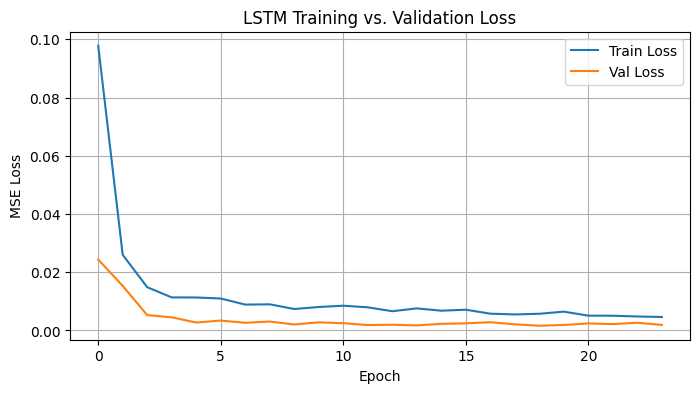

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


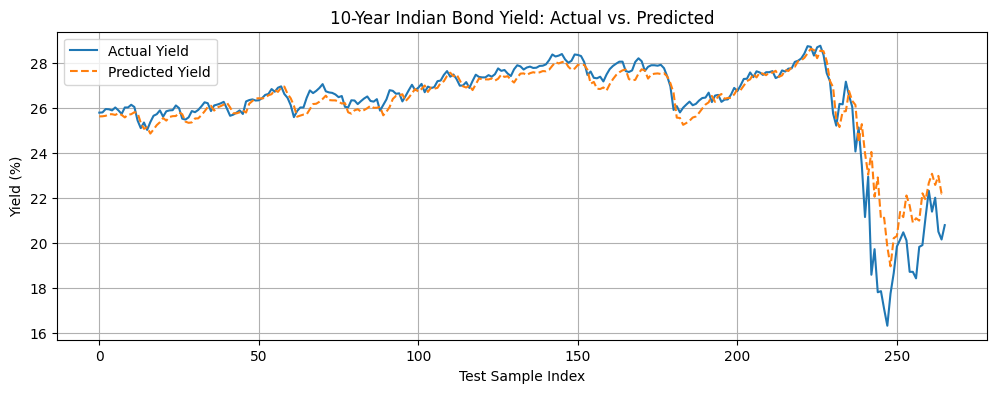

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# 1) Load technical indicators and clean yields
tech_df = pd.read_csv('bond_yield_technical_indicators.csv', parse_dates=['Date'],index_col='Date')
data = pd.read_csv('india_bond_yields_2010_2025.csv', parse_dates=['Date'],index_col='Date')
# Remove rows where 'yield' column has non-numeric entries
data = data[pd.to_numeric(data['10Y'], errors='coerce').notnull()]

# Convert yield to numeric explicitly
data['10Y'] = data['10Y'].astype(float)

#y_df    = pd.read_csv('india_bond_yields_2010_2025.csv', parse_dates=['Date']).set_index('Date')

features = [
    'Yield_Curve_Slope','Yield_Curvature','Level_Shift','Roll_Down',
    'Duration','Convexity','30y_5y_Spread','10y_1y_Spread',
    'NS_Level','NS_Slope','NS_Curvature'
]

print(len(tech_df))
# 2) Standardize the features (zero mean, unit variance)
X = tech_df[features].values
X_mean = X.mean(axis=0)
X_stdv = X.std(axis=0)
X_std = (X - X_mean) / X_stdv  # shape (n_samples, 11)

# 3) Manual PCA via covariance & eigen‐decomposition
cov = np.cov(X_std, rowvar=False)            # 11×11 covariance matrix
eigs, vecs = np.linalg.eigh(cov)             # eigs ascending
idx = np.argsort(eigs)[::-1]                 # sort descending
eigs_sorted = eigs[idx]
vecs_sorted = vecs[:, idx]

# 4) Keep top 3 PCs
n_pcs = 3
top_vecs = vecs_sorted[:, :n_pcs]            # 11×3
PCs = X_std.dot(top_vecs)                    # n_samples×3

print(tech_df)
# 5) Build a DataFrame of PCs and align yields by date
dates = tech_df.index[:len(PCs)]  # use index, not tech_df['Date']
pc_df = pd.DataFrame(PCs, columns=[f'PC{i+1}' for i in range(n_pcs)], index=dates)

pc_df['yield'] = pc_df.index.map(data['10Y'])
pc_df.dropna(subset=['yield'], inplace=True)


# 5) Create sequences (10-day lookback)
window = 10
X_seq, y_seq = [], []
for i in range(window, len(pc_df)):
    X_seq.append(pc_df[['PC1','PC2','PC3']].iloc[i-window:i].values)
    y_seq.append(pc_df['yield'].iloc[i])

X_seq = np.array(X_seq)    # (samples, window, 3)
y_seq = np.array(y_seq)    # (samples,)

# 6) Train/Test split (80/20)
split = int(0.8 * len(X_seq))
X_train, X_test = X_seq[:split], X_seq[split:]
y_train_orig    = y_seq[:split]
y_test_orig     = y_seq[split:]

# 7) Manual Min-Max scale on training targets
y_min, y_max = y_train_orig.min(), y_train_orig.max()
y_train = (y_train_orig - y_min) / (y_max - y_min)
y_test  = (y_test_orig  - y_min) / (y_max - y_min)

# 8) Build LSTM with dropout
model = Sequential([
    LSTM(32, activation='relu', return_sequences=True, input_shape=(window, 3)),
    Dropout(0.2),
    LSTM(16, activation='relu'),
    Dropout(0.2),
    Dense(1)
])
model.compile(optimizer='adam', loss='mse')

# 9) Early stopping & checkpoint
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ModelCheckpoint('best_lstm.h5', monitor='val_loss', save_best_only=True)
]

# 10) Train
history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=2
)

# 11) Plot loss curves
plt.figure(figsize=(8,4))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('LSTM Training vs. Validation Loss')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.legend(); plt.grid(True)
plt.show()

# 12) Predict & invert scaling
y_pred_scaled = model.predict(X_test).flatten()
y_pred = y_pred_scaled * (y_max - y_min) + y_min

# 13) Plot actual vs predicted
plt.figure(figsize=(12,4))
plt.plot(y_test_orig,    label='Actual Yield', linewidth=1.5)
plt.plot(y_pred, '--',   label='Predicted Yield')
plt.title('10-Year Indian Bond Yield: Actual vs. Predicted')
plt.xlabel('Test Sample Index'); plt.ylabel('Yield (%)')
plt.legend(); plt.grid(True)
plt.show()

                 PC1       PC2       PC3  yield
Date                                           
2014-12-10 -0.081447 -0.555183 -2.760115  29.72
2014-12-11  5.088029  3.753054 -3.297530  28.41
2014-12-12  2.444639 -1.360187 -1.746475  28.16
2014-12-15  2.928503 -0.509012 -1.835542  27.86
2014-12-16  2.301299 -1.704292 -1.512118  27.83
...              ...       ...       ...    ...
2020-04-13  3.267066  5.902983  1.392344  21.39
2020-04-14 -2.652862 -2.782995  3.623584  22.01
2020-04-15  4.632783  8.396522  1.424190  20.50
2020-04-16  0.976308  1.118086  3.725820  20.15
2020-04-17 -1.371291 -2.940765  4.378666  20.79

[1338 rows x 4 columns]


/opt/homebrew/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
9/9 ━━━━━━━━

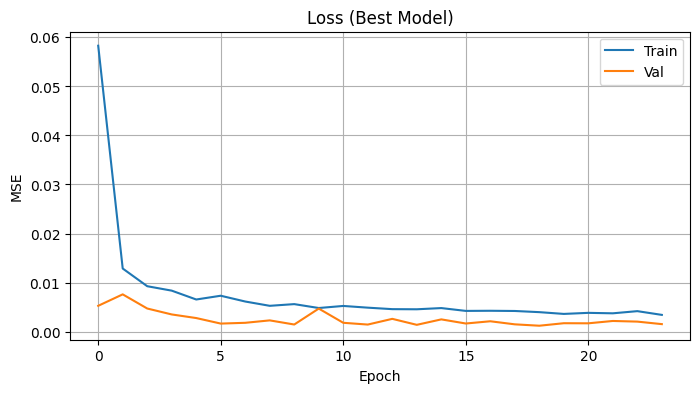

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


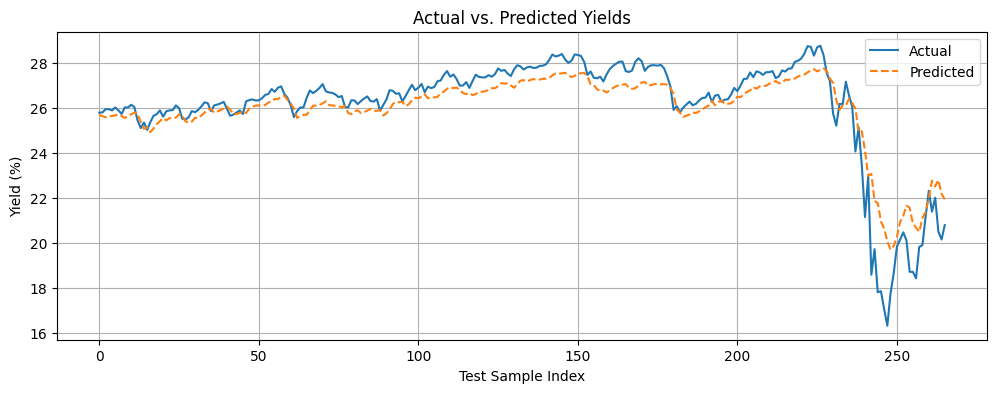

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
#from tensorflow.keras.optimizers.legacy import Adam  # use legacy optimizer on M1/M2
from keras.optimizers import Adam  # no ".legacy"
optimizer = Adam(learning_rate=0.001)
# 1) Load technical indicators and cleaned yields
tech_df = pd.read_csv('bond_yield_technical_indicators.csv', parse_dates=['Date'])
y_df    = pd.read_csv('india_bond_yields_2010_2025.csv', parse_dates=['Date']).set_index('Date')
# Remove rows where 'yield' column has non-numeric entries
data = data[pd.to_numeric(data['10Y'], errors='coerce').notnull()]

# Convert yield to numeric explicitly
data['10Y'] = data['10Y'].astype(float)

features = [
    'Yield_Curve_Slope','Yield_Curvature','Level_Shift','Roll_Down',
    'Duration','Convexity','30y_5y_Spread','10y_1y_Spread',
    'NS_Level','NS_Slope','NS_Curvature'
]

# 2) Standardize feature matrix
X = tech_df[features].values
X_mean, X_stdv = X.mean(axis=0), X.std(axis=0)
X_std = (X - X_mean) / X_stdv   # shape: (n_samples, 11)

# 3) Manual PCA → keep top 3 components
cov        = np.cov(X_std, rowvar=False)    # 11×11 covariance
eigs, vecs = np.linalg.eigh(cov)            # eigen decomposition
order      = np.argsort(eigs)[::-1]         # descending sort
top_vecs   = vecs[:, order[:3]]             # 11×3
PCs        = X_std.dot(top_vecs)            # n_samples×3

# 4) Build DataFrame of PCs and align yields by date
pc_df = pd.DataFrame(PCs, columns=['PC1','PC2','PC3'])
pc_df['Date']  = tech_df['Date']
pc_df['yield'] = pc_df['Date'].map(y_df['10Y'])
pc_df.dropna(subset=['yield'], inplace=True)
pc_df.set_index('Date', inplace=True)
print(pc_df)
# 5) Function to build sequences for a given window
def build_sequences(df, window):
    Xs, ys = [], []
    for i in range(window, len(df)):
        Xs.append(df[['PC1','PC2','PC3']].iloc[i-window:i].values)
        ys.append(df['yield'].iloc[i])
    Xs = np.array(Xs)
    ys = np.array(ys)
    # Min-Max scale on training portion of ys
    split = int(0.8 * len(ys))
    y_min, y_max = ys[:split].min(), ys[:split].max()
    ys_scaled = (ys - y_min) / (y_max - y_min)
    return Xs, ys_scaled, ys, y_min, y_max

# 6) Train/test split helper
def split_data(X, y_scaled, y_orig):
    split = int(0.8 * len(X))
    return (
        X[:split], X[split:],
        y_scaled[:split], y_scaled[split:],
        y_orig[:split], y_orig[split:]
    )

# 7) Simple R², MSE, MAE
def compute_metrics(y_true, y_pred):
    mse    = np.mean((y_true - y_pred)**2)
    mae    = np.mean(np.abs(y_true - y_pred))
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    r2     = 1 - ss_res/ss_tot
    return mse, mae, r2

# 8) Hyperparameter grids
windows  = [5, 10, 20]
units1   = [16, 32, 64]
units2   = [8, 16, 32]
dropouts = [0.1, 0.2, 0.3]
lrs      = [1e-3, 5e-4, 1e-4]

best = {'r2': -np.inf}

# 9) Grid search
for win in windows:
    Xs, ys_scaled, ys_orig, y_min, y_max = build_sequences(pc_df, win)
    X_tr, X_te, y_tr, y_te, y_tr_orig, y_te_orig = split_data(Xs, ys_scaled, ys_orig)
    for u1 in units1:
        for u2 in units2:
            for dr in dropouts:
                for lr in lrs:
                    model = Sequential([
                        LSTM(u1, return_sequences=True, input_shape=(win,3)),
                        Dropout(dr),
                        LSTM(u2),
                        Dropout(dr),
                        Dense(1)
                    ])
                    model.compile(optimizer=Adam(learning_rate=lr), loss='mse')
                    es = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
                    model.fit(
                        X_tr, y_tr,
                        epochs=20, batch_size=16,
                        validation_split=0.1,
                        callbacks=[es],
                        verbose=0
                    )
                    # predict & invert scaling
                    y_pred_s = model.predict(X_te).flatten()
                    y_pred   = y_pred_s * (y_max - y_min) + y_min
                    mse, mae, r2 = compute_metrics(y_te_orig, y_pred)
                    if r2 > best['r2']:
                        best.update({
                            'window': win, 'u1': u1, 'u2': u2,
                            'drop': dr, 'lr': lr, 'r2': r2,
                            'mse': mse, 'mae': mae
                        })
    print(f"Done window={win}")

print("Best config:", best)

# 10) Retrain best model on full training set & plot

# Unpack
win, u1, u2, dr, lr = best['window'], best['u1'], best['u2'], best['drop'], best['lr']
Xs, ys_scaled, ys_orig, y_min, y_max = build_sequences(pc_df, win)
X_tr, X_te, y_tr, y_te, y_tr_orig, y_te_orig = split_data(Xs, ys_scaled, ys_orig)

model = Sequential([
    LSTM(u1, return_sequences=True, input_shape=(win,3)),
    Dropout(dr),
    LSTM(u2),
    Dropout(dr),
    Dense(1)
])
#model.compile(optimizer=Adam(learning_rate=lr), loss='mse')
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss='mse')


es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(
    X_tr, y_tr,
    epochs=100, batch_size=16,
    validation_split=0.1,
    callbacks=[es],
    verbose=2
)

# Plot loss
plt.figure(figsize=(8,4))
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title('Loss (Best Model)')
plt.xlabel('Epoch'); plt.ylabel('MSE')
plt.legend(); plt.grid(True)
plt.show()

# Final predictions
y_pred_s = model.predict(X_te).flatten()
y_pred   = y_pred_s * (y_max - y_min) + y_min

plt.figure(figsize=(12,4))
plt.plot(y_te_orig,    label='Actual', linewidth=1.5)
plt.plot(y_pred, '--', label='Predicted')
plt.title('Actual vs. Predicted Yields')
plt.xlabel('Test Sample Index'); plt.ylabel('Yield (%)')
plt.legend(); plt.grid(True)
plt.show()

Epoch 1/50


/opt/homebrew/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


59/59 - 3s - 58ms/step - loss: 0.0738 - val_loss: 0.0041
Epoch 2/50
59/59 - 0s - 3ms/step - loss: 0.0187 - val_loss: 0.0046
Epoch 3/50
59/59 - 0s - 3ms/step - loss: 0.0160 - val_loss: 0.0069
Epoch 4/50
59/59 - 0s - 4ms/step - loss: 0.0126 - val_loss: 0.0026
Epoch 5/50
59/59 - 0s - 3ms/step - loss: 0.0098 - val_loss: 0.0028
Epoch 6/50
59/59 - 0s - 3ms/step - loss: 0.0090 - val_loss: 0.0032
Epoch 7/50
59/59 - 0s - 3ms/step - loss: 0.0077 - val_loss: 0.0049
Epoch 8/50
59/59 - 0s - 3ms/step - loss: 0.0081 - val_loss: 0.0023
Epoch 9/50
59/59 - 0s - 3ms/step - loss: 0.0069 - val_loss: 0.0025
Epoch 10/50
59/59 - 0s - 3ms/step - loss: 0.0063 - val_loss: 0.0025
Epoch 11/50
59/59 - 0s - 3ms/step - loss: 0.0066 - val_loss: 0.0027
Epoch 12/50
59/59 - 0s - 3ms/step - loss: 0.0065 - val_loss: 0.0021
Epoch 13/50
59/59 - 0s - 3ms/step - loss: 0.0058 - val_loss: 0.0028
Epoch 14/50
59/59 - 0s - 3ms/step - loss: 0.0056 - val_loss: 0.0028
Epoch 15/50
59/59 - 0s - 3ms/step - loss: 0.0054 - val_loss: 0.0022

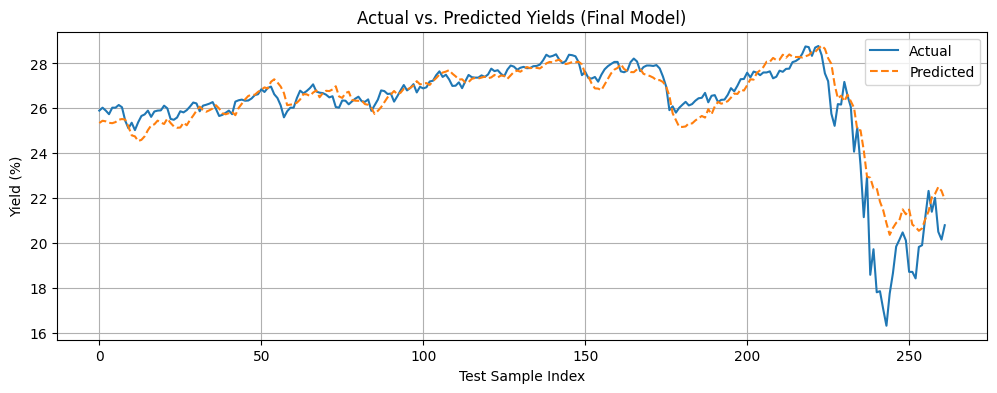

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
#from tensorflow.keras.optimizers.legacy import Adam
from keras.optimizers import Adam  # no ".legacy"
optimizer = Adam(learning_rate=0.001)

# --- 1) LOAD & MERGE -------------------------------------------------------
tech_df = pd.read_csv('bond_yield_technical_indicators.csv', parse_dates=['Date'])
y_df    = pd.read_csv('india_bond_yields_2010_2025.csv', parse_dates=['Date']).set_index('Date')
# Remove rows where 'yield' column has non-numeric entries
data = data[pd.to_numeric(data['10Y'], errors='coerce').notnull()]

# Convert yield to numeric explicitly
data['10Y'] = data['10Y'].astype(float)
# Map yields into tech_df
tech_df['yield'] = tech_df['Date'].map(y_df['10Y'])
tech_df.dropna(subset=['yield'], inplace=True)

# --- 2) FEATURE ENGINEERING ------------------------------------------------
df = tech_df.copy()

# rolling volatility, moving averages, momentum, rate-of-change
df['vol_20']   = df['yield'].rolling(20).std()
df['ma5']      = df['yield'].rolling(5).mean()
df['ma20']     = df['yield'].rolling(20).mean()
df['momentum'] = df['ma5'] - df['ma20']
df['roc5']     = df['yield'].pct_change(5)

# seasonal dummies: day-of-week & month
df['dow']   = df['Date'].dt.weekday
df['month'] = df['Date'].dt.month

# drop initial NaNs
df.dropna(inplace=True)

# winsorize to [1%,99%] to cap outliers
for col in ['vol_20','momentum','roc5']:
    lo, hi = df[col].quantile([0.01,0.99])
    df[col] = df[col].clip(lo, hi)

# one-hot encode dow, month
df = pd.get_dummies(df, columns=['dow','month'], prefix=['dow','m'])

# regime segmentation by median vol_20
median_vol = df['vol_20'].median()
df['regime'] = (df['vol_20'] > median_vol).astype(int)
df = pd.get_dummies(df, columns=['regime'], prefix='regime')

# --- 3) PREPARE FEATURE LIST & CAST ----------------------------------------
base_feats = [
    'Yield_Curve_Slope','Yield_Curvature','Level_Shift','Roll_Down',
    'Duration','Convexity','30y_5y_Spread','10y_1y_Spread',
    'NS_Level','NS_Slope','NS_Curvature',
    'vol_20','momentum','roc5'
]
dummy_feats = [c for c in df.columns if c.startswith('dow_') or c.startswith('m_') or c.startswith('regime_')]
all_feats   = base_feats + dummy_feats

# force numeric dtype
df[all_feats] = df[all_feats].astype(float)

# target
df['yield'] = df['yield'].astype(float)

# --- 4) EXTRACT X, y, DATES ------------------------------------------------
X = df[all_feats].values
y = df['yield'].values
dates = df['Date'].values

# standardize X
X_mean, X_stdv = X.mean(axis=0), X.std(axis=0)
X_std = (X - X_mean) / X_stdv

# --- 5) MANUAL PCA (3 COMPONENTS) ------------------------------------------
cov    = np.cov(X_std, rowvar=False)
eigs, vecs = np.linalg.eigh(cov)
order = np.argsort(eigs)[::-1]
top_vecs = vecs[:, order[:3]]        # shape (n_features,3)
PCs = X_std.dot(top_vecs)            # shape (n_samples,3)

pc_df = pd.DataFrame(PCs, columns=['PC1','PC2','PC3'])
pc_df['yield'] = y
pc_df['Date']  = dates

# --- 6) SEQUENCE BUILDER & SPLIT -------------------------------------------
def build_sequences(df, window):
    Xs, ys = [], []
    for i in range(window, len(df)):
        Xs.append(df[['PC1','PC2','PC3']].iloc[i-window:i].values)
        ys.append(df['yield'].iloc[i])
    Xs = np.array(Xs)
    ys = np.array(ys)
    # Min-Max scale on train portion
    split = int(0.8 * len(ys))
    y_min, y_max = ys[:split].min(), ys[:split].max()
    ys_scaled = (ys - y_min) / (y_max - y_min)
    return Xs, ys_scaled, ys, y_min, y_max

def split_data(Xs, ys_scaled, ys_orig):
    split = int(0.8 * len(Xs))
    return (
        Xs[:split], Xs[split:],
        ys_scaled[:split], ys_scaled[split:],
        ys_orig[:split], ys_orig[split:]
    )

# --- 7) TRAIN & EVALUATE --------------------------------------------------
window = 10
Xs, ys_scaled, ys_orig, y_min, y_max = build_sequences(pc_df, window)
X_tr, X_te, y_tr, y_te, y_tr_orig, y_te_orig = split_data(Xs, ys_scaled, ys_orig)

model = Sequential([
    LSTM(32, return_sequences=True, input_shape=(window,3)),
    Dropout(0.2),
    LSTM(16),
    Dropout(0.2),
    Dense(1, use_bias=True)
])
#model.compile(optimizer=Adam(1e-3), loss='mse')
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse')
es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
model.fit(
    X_tr, y_tr,
    epochs=50, batch_size=16,
    validation_split=0.1,
    callbacks=[es],
    verbose=2
)

# predict & invert scale
y_pred_s = model.predict(X_te, verbose=0).flatten()
y_pred   = y_pred_s * (y_max - y_min) + y_min

# metrics
mse    = np.mean((y_te_orig - y_pred)**2)
mae    = np.mean(np.abs(y_te_orig - y_pred))
ss_res = np.sum((y_te_orig - y_pred)**2)
ss_tot = np.sum((y_te_orig - y_te_orig.mean())**2)
r2     = 1 - ss_res/ss_tot

print(f"Test MSE: {mse:.4f}   MAE: {mae:.4f}   R²: {r2:.4f}")

# --- 8) PLOT ---------------------------------------------------------------
plt.figure(figsize=(12,4))
plt.plot(y_te_orig,    label='Actual', linewidth=1.5)
plt.plot(y_pred, '--', label='Predicted')
plt.title('Actual vs. Predicted Yields (Final Model)')
plt.xlabel('Test Sample Index'); plt.ylabel('Yield (%)')
plt.legend(); plt.grid(True)
plt.show()

/opt/homebrew/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/opt/homebrew/lib/python3.11/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  activation=None,


Test MSE: 1.6833  MAE: 1.0307  R²: 0.6996


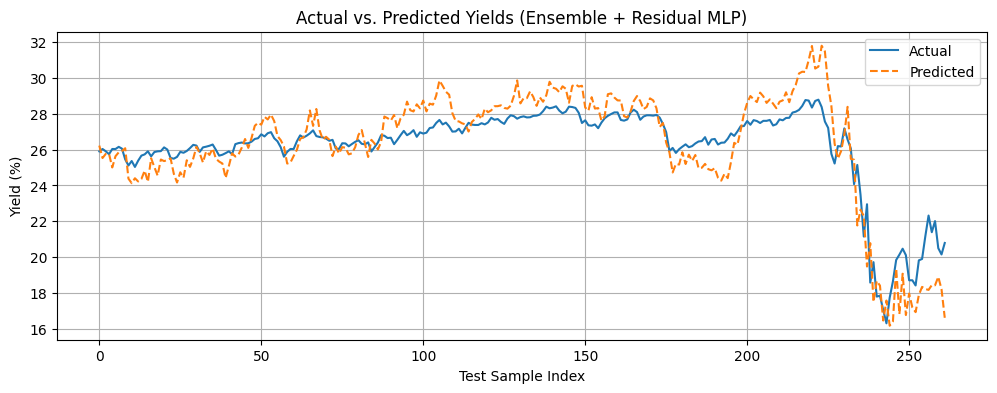

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
#from tensorflow.keras.optimizers.legacy import Adam
from keras.optimizers import Adam  # no ".legacy"
optimizer = Adam(learning_rate=0.001)

# --- 1) LOAD & MERGE -------------------------------------------------------
tech_df = pd.read_csv('bond_yield_technical_indicators.csv', parse_dates=['Date'])
y_df    = pd.read_csv('india_bond_yields_2010_2025.csv', parse_dates=['Date']).set_index('Date')
# Remove rows where 'yield' column has non-numeric entries
y_df = y_df[pd.to_numeric(y_df['10Y'], errors='coerce').notnull()]

# Convert yield to numeric explicitly
y_df['10Y'] = y_df['10Y'].astype(float)
tech_df['yield'] = tech_df['Date'].map(y_df['10Y'])
tech_df.dropna(subset=['yield'], inplace=True)

# --- 2) FEATURE ENGINEERING ------------------------------------------------
df = tech_df.copy()

# AR lags of yield (1–5 days)
for lag in range(1, 6):
    df[f'y_lag{lag}'] = df['yield'].shift(lag)

# rolling volatility, momentum, ROC
df['vol_20']   = df['yield'].rolling(20).std()
df['ma5']      = df['yield'].rolling(5).mean()
df['ma20']     = df['yield'].rolling(20).mean()
df['momentum'] = df['ma5'] - df['ma20']
df['roc5']     = df['yield'].pct_change(5)

# seasonal dummies
df['dow']   = df['Date'].dt.weekday
df['month'] = df['Date'].dt.month
df.dropna(inplace=True)

# winsorize extremes
for col in ['vol_20','momentum','roc5']:
    lo, hi = df[col].quantile([0.01,0.99])
    df[col] = df[col].clip(lo, hi)

# encode dummies
df = pd.get_dummies(df, columns=['dow','month'], prefix=['dow','m'])

# regime by vol_20
median_vol = df['vol_20'].median()
df['regime'] = (df['vol_20'] > median_vol).astype(int)
df = pd.get_dummies(df, columns=['regime'], prefix='regime')

# select features
base_feats  = [
    'Yield_Curve_Slope','Yield_Curvature','Level_Shift','Roll_Down',
    'Duration','Convexity','30y_5y_Spread','10y_1y_Spread',
    'NS_Level','NS_Slope','NS_Curvature',
    'y_lag1','y_lag2','y_lag3','y_lag4','y_lag5',
    'vol_20','momentum','roc5'
]
dummy_feats = [c for c in df.columns if c.startswith('dow_') or c.startswith('m_') or c.startswith('regime_')]
all_feats   = base_feats + dummy_feats

# force float dtype
df[all_feats] = df[all_feats].astype(float)
df['yield']  = df['yield'].astype(float)

# --- 3) STANDARDIZE FEATURES ----------------------------------------------
X = df[all_feats].values
y = df['yield'].values
dates = df['Date'].values
X_mean, X_std = X.mean(axis=0), X.std(axis=0)
X = (X - X_mean) / X_std

# --- 4) BUILD SEQUENCES ----------------------------------------------------
def build_sequences(X, y, window):
    Xs, ys = [], []
    for i in range(window, len(X)):
        Xs.append(X[i-window:i])
        ys.append(y[i])
    Xs = np.array(Xs)
    ys = np.array(ys)
    # min-max scale target on training portion
    split = int(0.8 * len(ys))
    y_min, y_max = ys[:split].min(), ys[:split].max()
    ys_scaled = (ys - y_min) / (y_max - y_min)
    return Xs, ys_scaled, ys, y_min, y_max

def split_data(Xs, ys_scaled, ys_orig):
    split = int(0.8 * len(Xs))
    return (
        Xs[:split], Xs[split:],
        ys_scaled[:split], ys_scaled[split:],
        ys_orig[:split], ys_orig[split:]
    )

window = 10
Xs, ys_s, ys_o, y_min, y_max = build_sequences(X, y, window)
X_tr, X_te, y_tr, y_te, y_tr_o, y_te_o = split_data(Xs, ys_s, ys_o)

# --- 5) ENSEMBLE OF LSTMs -------------------------------------------------
def make_model():
    m = Sequential([
        LSTM(32, return_sequences=True, input_shape=(window, X.shape[1])),
        Dropout(0.2),
        LSTM(16),
        Dropout(0.2),
        Dense(1, use_bias=True)
    ])
    m.compile(optimizer=Adam(1e-3), loss='mse')
    return m

ensemble_preds = []
for seed in [0,1,2]:
    tf.random.set_seed(seed)
    model = make_model()
    es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    model.fit(
        X_tr, y_tr,
        epochs=50, batch_size=16,
        validation_split=0.1,
        callbacks=[es],
        verbose=0
    )
    p = model.predict(X_te, verbose=0).flatten()
    ensemble_preds.append(p)

# average and invert scale
y_pred_ens = np.mean(ensemble_preds, axis=0)*(y_max-y_min) + y_min

# --- 6) RESIDUAL MLP CORRECTION -------------------------------------------
residuals = y_te_o - y_pred_ens
# flatten X_te for MLP
X_te_flat = X_te.reshape(X_te.shape[0], -1)
X_tr_flat = X_tr.reshape(X_tr.shape[0], -1)
# train MLP on training set residuals
mlp = Sequential([
    Dense(32, activation='relu', input_shape=(X_tr_flat.shape[1],)),
    Dense(1, use_bias=True)
])
mlp.compile(optimizer=Adam(1e-3), loss='mse')
mlp.fit(X_tr_flat, (y_tr_o := (y_tr*(y_max-y_min)+y_min)) - 
        np.mean(y_pred_ens[:len(X_tr_flat)]), 
        epochs=20, batch_size=16, verbose=0)

# predict residuals and correct
resid_pred = mlp.predict(X_te_flat, verbose=0).flatten()
y_pred_final = y_pred_ens + resid_pred

# --- 7) EVALUATE -----------------------------------------------------------
mse = np.mean((y_te_o - y_pred_final)**2)
mae = np.mean(np.abs(y_te_o - y_pred_final))
ss_res = np.sum((y_te_o - y_pred_final)**2)
ss_tot = np.sum((y_te_o - y_te_o.mean())**2)
r2 = 1 - ss_res/ss_tot
print(f"Test MSE: {mse:.4f}  MAE: {mae:.4f}  R²: {r2:.4f}")

# --- 8) PLOT ---------------------------------------------------------------
plt.figure(figsize=(12,4))
plt.plot(y_te_o,    label='Actual', linewidth=1.5)
plt.plot(y_pred_final, '--', label='Predicted')
plt.title('Actual vs. Predicted Yields (Ensemble + Residual MLP)')
plt.xlabel('Test Sample Index'); plt.ylabel('Yield (%)')
plt.legend(); plt.grid(True)
plt.show()

Epoch 1/50


/opt/homebrew/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


59/59 - 4s - 67ms/step - loss: 0.1589 - val_loss: 0.2589
Epoch 2/50
59/59 - 0s - 4ms/step - loss: 0.0377 - val_loss: 0.1586
Epoch 3/50
59/59 - 0s - 3ms/step - loss: 0.0314 - val_loss: 0.1651
Epoch 4/50
59/59 - 0s - 3ms/step - loss: 0.0255 - val_loss: 0.1363
Epoch 5/50
59/59 - 0s - 3ms/step - loss: 0.0237 - val_loss: 0.1417
Epoch 6/50
59/59 - 0s - 3ms/step - loss: 0.0204 - val_loss: 0.1104
Epoch 7/50
59/59 - 0s - 3ms/step - loss: 0.0188 - val_loss: 0.0852
Epoch 8/50
59/59 - 0s - 3ms/step - loss: 0.0183 - val_loss: 0.0847
Epoch 9/50
59/59 - 0s - 3ms/step - loss: 0.0159 - val_loss: 0.0866
Epoch 10/50
59/59 - 0s - 3ms/step - loss: 0.0159 - val_loss: 0.0681
Epoch 11/50
59/59 - 0s - 3ms/step - loss: 0.0152 - val_loss: 0.0657
Epoch 12/50
59/59 - 0s - 3ms/step - loss: 0.0155 - val_loss: 0.0753
Epoch 13/50
59/59 - 0s - 3ms/step - loss: 0.0147 - val_loss: 0.0619
Epoch 14/50
59/59 - 0s - 3ms/step - loss: 0.0140 - val_loss: 0.0708
Epoch 15/50
59/59 - 0s - 3ms/step - loss: 0.0130 - val_loss: 0.0660

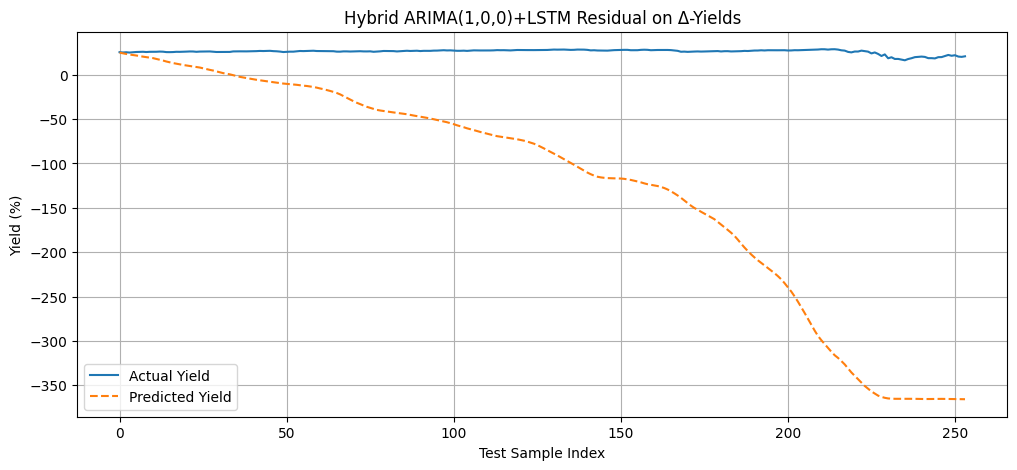

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
#from tensorflow.keras.optimizers.legacy import Adam
from keras.optimizers import Adam  # no ".legacy"
optimizer = Adam(learning_rate=0.001)

# 1) LOAD & MERGE ----------------------------------------------------------------
tech_df = pd.read_csv('bond_yield_technical_indicators.csv', parse_dates=['Date'])
y_df    = pd.read_csv('india_bond_yields_2010_2025.csv', parse_dates=['Date']).set_index('Date')
# Remove rows where 'yield' column has non-numeric entries
y_df = y_df[pd.to_numeric(y_df['10Y'], errors='coerce').notnull()]

# Convert yield to numeric explicitly
tech_df['yield'] = tech_df['Date'].map(y_df['10Y'])
tech_df.dropna(subset=['yield'], inplace=True)


# 2) FEATURE ENGINEERING ---------------------------------------------------------
df = tech_df.copy()

# 2a) AR lags of the yield level (we still need them as features)
for lag in range(1, 6):
    df[f'y_lag{lag}'] = df['yield'].shift(lag)

# 2b) Classic momentum/volatility indicators on levels
df['vol_20']   = df['yield'].rolling(20).std()
df['ma5']      = df['yield'].rolling(5).mean()
df['ma20']     = df['yield'].rolling(20).mean()
df['momentum'] = df['ma5'] - df['ma20']
df['roc5']     = df['yield'].pct_change(5)

# 2c) Seasonal dummies
df['dow']   = df['Date'].dt.weekday
df['month'] = df['Date'].dt.month

# 2d) Drop NA from all rolling / lag features
df.dropna(inplace=True)

# 2e) Winsorize to tame outliers
for c in ['vol_20','momentum','roc5']:
    lo, hi = df[c].quantile([0.01,0.99])
    df[c]  = df[c].clip(lo,hi)

# 2f) One-hot encode dow, month
df = pd.get_dummies(df, columns=['dow','month'], prefix=['dow','m'])

# 2g) Regime dummy by high/low volatility
med_vol = df['vol_20'].median()
df['regime'] = (df['vol_20'] > med_vol).astype(int)
df = pd.get_dummies(df, columns=['regime'], prefix='regime')

# 3) DELTA TARGET & FINAL FEATURE SET ------------------------------------------
# target = daily change (delta) of the yield level
df['d_yield'] = df['yield'].diff()
df.dropna(subset=['d_yield'], inplace=True)

# assemble feature list
base_feats   = [
    'Yield_Curve_Slope','Yield_Curvature','Level_Shift','Roll_Down',
    'Duration','Convexity','30y_5y_Spread','10y_1y_Spread',
    'NS_Level','NS_Slope','NS_Curvature',
    'y_lag1','y_lag2','y_lag3','y_lag4','y_lag5',
    'vol_20','momentum','roc5'
]
dummy_feats  = [c for c in df.columns if c.startswith('dow_') or 
                c.startswith('m_') or c.startswith('regime_')]
all_feats    = base_feats + dummy_feats

# force floats
df[all_feats]  = df[all_feats].astype(float)
df['d_yield']  = df['d_yield'].astype(float)
df['yield']    = df['yield'].astype(float)  # keep for reconstruction

# 4) STANDARDIZE FEATURES ------------------------------------------------------
X_full = df[all_feats].values
y_full = df['d_yield'].values
dates  = df['Date'].values

X_mean, X_std = X_full.mean(0), X_full.std(0)
X_stdzd       = (X_full - X_mean) / X_std

# 5) TRAIN/TEST SPLIT ----------------------------------------------------------
split = int(0.8 * len(df))
X_train, X_test = X_stdzd[:split], X_stdzd[split:]
y_train, y_test = y_full[:split],    y_full[split:]
levels_train_end = df['yield'].iloc[split-1]  # for reconstruction

# 6) ARIMA(1,0,0) FROM SCRATCH -------------------------------------------------
# Fit phi in:   delta[t] = phi * delta[t-1]  +  eps[t]
d_lag = y_train[:-1]
d_tgt = y_train[1:]
phi = (d_lag @ d_tgt) / (d_lag @ d_lag)

# in-sample AR(1) predictions & residuals
ar_pred_train = phi * np.concatenate([[y_train[0]], y_train[:-1]])
resid_train   = y_train - ar_pred_train

# 7) LSTM ON THE RESIDUALS -----------------------------------------------------
# Build sequences for the LSTM (on residuals)
window = 10
def build_seq(X, y):
    Xs, ys = [], []
    for i in range(window, len(y)):
        Xs.append(X[i-window:i])
        ys.append(y[i])
    return np.array(Xs), np.array(ys)

Xtr_seq, ytr_resid = build_seq(X_train, resid_train)
Xte_seq, yte_delta = build_seq(X_test,  y_test)  # delta test target

# scale residual target into [0,1] for stable training
r_lo, r_hi = ytr_resid.min(), ytr_resid.max()
ytr_resid_s = (ytr_resid - r_lo) / (r_hi - r_lo)

# build & train
model = Sequential([
    LSTM(32, return_sequences=True, input_shape=(window, X_full.shape[1])),
    Dropout(0.2),
    LSTM(16),
    Dropout(0.2),
    Dense(1)
])
model.compile(optimizer=Adam(1e-3), loss='mse')
es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
model.fit(
    Xtr_seq, ytr_resid_s,
    epochs=50, batch_size=16,
    validation_split=0.1,
    callbacks=[es],
    verbose=2
)

# 8) FORECAST TEST DELTAS -----------------------------------------------------
# AR part on test deltas: delta[t] = phi * delta[t-1]
# we need the last train delta as "previous"
last_train_delta = y_train[-1]
ar_pred_test = []
prev = last_train_delta
for true_delta in y_test:
    p = phi * prev
    ar_pred_test.append(p)
    prev = true_delta   # one-step “rolling” AR

ar_pred_test = np.array(ar_pred_test)

# LSTM residual forecast (invert scale)
resid_pred_s  = model.predict(Xte_seq, verbose=0).flatten()
resid_pred    = resid_pred_s * (r_hi - r_lo) + r_lo

# align lengths: Xte_seq starts at index=window into test,
# so we need to pad the first window with AR-only for the first few points
pad = window
ar_full    = ar_pred_test[pad:]
delta_preds = ar_full + resid_pred

# 9) RECONSTRUCT YIELD LEVELS -------------------------------------------------
# Start from levels_train_end, then cumulative sum
y_level_pred = levels_train_end + np.cumsum(delta_preds)
y_level_true = df['yield'].values[split+pad:]

# 10) METRICS & PLOT ----------------------------------------------------------
mse    = np.mean((y_level_true - y_level_pred)**2)
mae    = np.mean(np.abs(y_level_true - y_level_pred))
ss_res = np.sum((y_level_true - y_level_pred)**2)
ss_tot = np.sum((y_level_true - y_level_true.mean())**2)
r2     = 1 - ss_res/ss_tot

print(f"Test MSE: {mse:.4f}   MAE: {mae:.4f}   R²: {r2:.4f}")

plt.figure(figsize=(12,5))
plt.plot(y_level_true,    label='Actual Yield', linewidth=1.5)
plt.plot(y_level_pred, '--', label='Predicted Yield')
plt.title('Hybrid ARIMA(1,0,0)+LSTM Residual on Δ-Yields')
plt.xlabel('Test Sample Index'); plt.ylabel('Yield (%)')
plt.legend(); plt.grid(True)
plt.show()

Epoch 1/50


/opt/homebrew/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


59/59 - 3s - 57ms/step - loss: 0.1064 - val_loss: 0.0616
Epoch 2/50
59/59 - 0s - 3ms/step - loss: 0.0915 - val_loss: 0.0667
Epoch 3/50
59/59 - 0s - 3ms/step - loss: 0.0842 - val_loss: 0.0665
Epoch 4/50
59/59 - 0s - 3ms/step - loss: 0.0836 - val_loss: 0.0685
Epoch 5/50
59/59 - 0s - 5ms/step - loss: 0.0792 - val_loss: 0.0708
Epoch 6/50
59/59 - 0s - 4ms/step - loss: 0.0792 - val_loss: 0.0746


Test MSE: 49.0160   MAE: 5.3450   R²: -7.4815


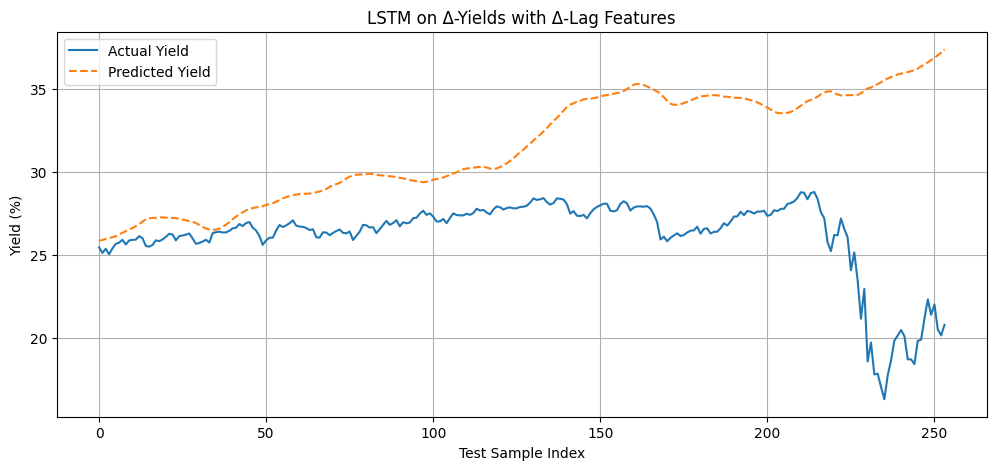

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
#from tensorflow.keras.optimizers.legacy import Adam
from keras.optimizers import Adam  # no ".legacy"
optimizer = Adam(learning_rate=0.001)

# 1) LOAD & MERGE ------------------------------------------------------------
tech_df = pd.read_csv('bond_yield_technical_indicators.csv', parse_dates=['Date'])
y_df    = pd.read_csv('india_bond_yields_2010_2025.csv', parse_dates=['Date']).set_index('Date')
# Remove rows where 'yield' column has non-numeric entries
y_df = y_df[pd.to_numeric(y_df['10Y'], errors='coerce').notnull()]

# map the 10Y yield onto the tech indicators
tech_df['yield'] = tech_df['Date'].map(y_df['10Y'])
tech_df.dropna(subset=['yield'], inplace=True)

# 2) FEATURE ENGINEERING -----------------------------------------------------
df = tech_df.copy()

# 2a) target = daily delta of yield
df['d_yield'] = df['yield'].diff()

# 2b) lagged deltas (AR features)
for lag in range(1, 6):
    df[f'd_lag{lag}'] = df['d_yield'].shift(lag)

# 2c) additional technical features on levels
df['vol_20']   = df['yield'].rolling(20).std()
df['ma5']      = df['yield'].rolling(5).mean()
df['ma20']     = df['yield'].rolling(20).mean()
df['momentum'] = df['ma5'] - df['ma20']
df['roc5']     = df['yield'].pct_change(5)

# 2d) seasonal dummies
df['dow']   = df['Date'].dt.weekday
df['month'] = df['Date'].dt.month

# drop NA from all of the above
df.dropna(inplace=True)

# winsorize extremes
for col in ['vol_20', 'momentum', 'roc5']:
    lo, hi = df[col].quantile([0.01, 0.99])
    df[col] = df[col].clip(lo, hi)

# one-hot encode dow/month
df = pd.get_dummies(df, columns=['dow','month'], prefix=['dow','m'])

# regime flag by high/low vol
med_vol = df['vol_20'].median()
df['regime'] = (df['vol_20'] > med_vol).astype(int)
df = pd.get_dummies(df, columns=['regime'], prefix='regime')

# 3) ASSEMBLE FEATURES & TARGET ---------------------------------------------
# base features + d_lags + dummies
base_feats  = [
    'Yield_Curve_Slope','Yield_Curvature','Level_Shift','Roll_Down',
    'Duration','Convexity','30y_5y_Spread','10y_1y_Spread',
    'NS_Level','NS_Slope','NS_Curvature',
    'vol_20','momentum','roc5'
]
delta_lags  = [f'd_lag{i}' for i in range(1,6)]
dummy_feats = [c for c in df.columns if c.startswith('dow_') or 
               c.startswith('m_')   or c.startswith('regime_')]
all_feats   = base_feats + delta_lags + dummy_feats

# force numeric dtype
df[all_feats] = df[all_feats].astype(float)
df['d_yield'] = df['d_yield'].astype(float)
df['yield']   = df['yield'].astype(float)  # keep for reconstruction

# 4) STANDARDIZE FEATURES ----------------------------------------------------
X = df[all_feats].values
y = df['d_yield'].values
dates = df['Date'].values

X_mean, X_std = X.mean(axis=0), X.std(axis=0)
X_scaled = (X - X_mean) / X_std

# 5) TRAIN/TEST SPLIT --------------------------------------------------------
split = int(0.8 * len(df))
X_train, X_test = X_scaled[:split], X_scaled[split:]
y_train, y_test = y[:split],       y[split:]

# keep last in‐sample level to reconstruct
level_last = df['yield'].values[split-1]

# 6) BUILD SEQUENCES ---------------------------------------------------------
window = 10
def build_seq(X, y, window):
    Xs, ys = [], []
    for i in range(window, len(y)):
        Xs.append(X[i-window:i])
        ys.append(y[i])
    return np.array(Xs), np.array(ys)

X_tr_seq, y_tr_seq = build_seq(X_train, y_train, window)
X_te_seq, y_te_seq = build_seq(X_test,  y_test,  window)

# 7) TRAIN A SINGLE DELTA-LSTM -----------------------------------------------
model = Sequential([
    LSTM(32, return_sequences=True, input_shape=(window, X.shape[1])),
    Dropout(0.2),
    LSTM(16),
    Dropout(0.2),
    Dense(1)
])
model.compile(optimizer=Adam(1e-3), loss='mse')

es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
history = model.fit(
    X_tr_seq, y_tr_seq,
    epochs=50, batch_size=16,
    validation_split=0.1,
    callbacks=[es],
    verbose=2
)

# 8) FORECAST DELTAS & RECONSTRUCT LEVELS ------------------------------------
# predict deltas on test
delta_pred = model.predict(X_te_seq, verbose=0).flatten()

# reconstruct yields
y_pred_level = [level_last]
for d in delta_pred:
    y_pred_level.append(y_pred_level[-1] + d)
y_pred_level = np.array(y_pred_level[1:])  # drop initial

# actual levels on test
y_true_level = df['yield'].values[split:][window:]

# 9) EVALUATE ---------------------------------------------------------------
mse    = np.mean((y_true_level - y_pred_level)**2)
mae    = np.mean(np.abs(y_true_level - y_pred_level))
ss_res = np.sum((y_true_level - y_pred_level)**2)
ss_tot = np.sum((y_true_level - y_true_level.mean())**2)
r2     = 1 - ss_res/ss_tot

print(f"Test MSE: {mse:.4f}   MAE: {mae:.4f}   R²: {r2:.4f}")

# 10) PLOT RESULTS ----------------------------------------------------------
plt.figure(figsize=(12,5))
plt.plot(y_true_level,    label='Actual Yield', linewidth=1.5)
plt.plot(y_pred_level, '--', label='Predicted Yield')
plt.title('LSTM on Δ-Yields with Δ-Lag Features')
plt.xlabel('Test Sample Index')
plt.ylabel('Yield (%)')
plt.legend()
plt.grid(True)
plt.show()

Epoch 1/50
59/59 - 4s - 61ms/step - delta_loss: 0.2292 - level_loss: 636.3151 - loss: 318.6727 - val_delta_loss: 0.1385 - val_level_loss: 536.9218 - val_loss: 263.7338
Epoch 2/50
59/59 - 0s - 3ms/step - delta_loss: 0.4459 - level_loss: 413.6598 - loss: 207.3768 - val_delta_loss: 0.0945 - val_level_loss: 377.7922 - val_loss: 185.1322
Epoch 3/50
59/59 - 0s - 3ms/step - delta_loss: 0.4391 - level_loss: 329.1333 - loss: 164.9577 - val_delta_loss: 0.0826 - val_level_loss: 336.2281 - val_loss: 165.5717
Epoch 4/50
59/59 - 0s - 3ms/step - delta_loss: 0.4335 - level_loss: 288.1870 - loss: 144.5039 - val_delta_loss: 0.0822 - val_level_loss: 306.9322 - val_loss: 151.5578
Epoch 5/50
59/59 - 0s - 3ms/step - delta_loss: 0.3518 - level_loss: 251.5573 - loss: 126.1456 - val_delta_loss: 0.0764 - val_level_loss: 281.7785 - val_loss: 139.5793
Epoch 6/50
59/59 - 0s - 3ms/step - delta_loss: 0.3216 - level_loss: 225.2011 - loss: 112.8371 - val_delta_loss: 0.0771 - val_level_loss: 260.2600 - val_loss: 129.28

Test MSE: 53.1138   MAE: 4.9613   R²: -8.3762


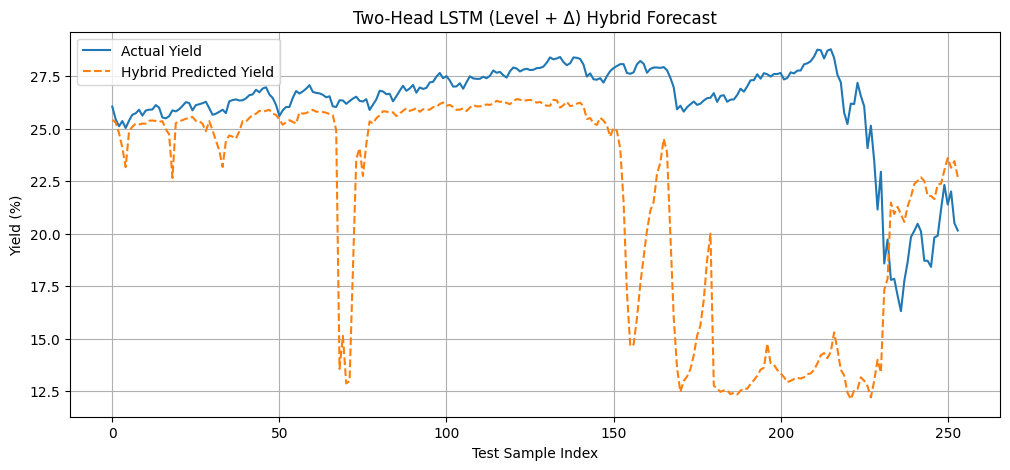

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
#from tensorflow.keras.callbacks import EarlyStopping
#from tensorflow.keras.optimizers.legacy import Adam
from keras.optimizers import Adam  # no ".legacy"
optimizer = Adam(learning_rate=0.001)
from keras.callbacks import EarlyStopping

# 1) LOAD & MERGE ----------------------------------------------------------------
tech_df = pd.read_csv('bond_yield_technical_indicators.csv', parse_dates=['Date'])
y_df    = pd.read_csv('india_bond_yields_2010_2025.csv', parse_dates=['Date']).set_index('Date')
# Remove rows where 'yield' column has non-numeric entries
y_df = y_df[pd.to_numeric(y_df['10Y'], errors='coerce').notnull()]
tech_df['yield'] = tech_df['Date'].map(y_df['10Y'])
tech_df.dropna(subset=['yield'], inplace=True)

# 2) FEATURE ENGINEERING --------------------------------------------------------
df = tech_df.copy()

# 2a) compute target and delta‐lags
df['d_yield'] = df['yield'].diff()
for lag in range(1, 6):
    df[f'd_lag{lag}'] = df['d_yield'].shift(lag)

# 2b) classic technicals on levels
df['vol_20']   = df['yield'].rolling(20).std()
df['ma5']      = df['yield'].rolling(5).mean()
df['ma20']     = df['yield'].rolling(20).mean()
df['momentum'] = df['ma5'] - df['ma20']
df['roc5']     = df['yield'].pct_change(5)

# 2c) seasonal dummies & regime
df['dow']   = df['Date'].dt.weekday
df['month'] = df['Date'].dt.month

# drop NAs
df.dropna(inplace=True)

# winsorize
for c in ['vol_20','momentum','roc5']:
    lo, hi = df[c].quantile([0.01,0.99])
    df[c] = df[c].clip(lo,hi)

df = pd.get_dummies(df, columns=['dow','month'], prefix=['dow','m'])
df['regime'] = (df['vol_20'] > df['vol_20'].median()).astype(int)
df = pd.get_dummies(df, columns=['regime'], prefix='regime')

# 2d) next‐day level target
df['y_next'] = df['yield'].shift(-1)
df.dropna(subset=['y_next','d_yield'], inplace=True)

# 3) ASSEMBLE FEATURES & TARGET -------------------------------------------------
base_feats  = [
  'Yield_Curve_Slope','Yield_Curvature','Level_Shift','Roll_Down',
  'Duration','Convexity','30y_5y_Spread','10y_1y_Spread',
  'NS_Level','NS_Slope','NS_Curvature',
  'vol_20','momentum','roc5'
]
delta_lags  = [f'd_lag{i}' for i in range(1,6)]
dummy_feats = [c for c in df.columns if c.startswith('dow_') or 
               c.startswith('m_')   or c.startswith('regime_')]
all_feats   = base_feats + delta_lags + dummy_feats

X = df[all_feats].astype(float).values
y_level = df['y_next'].values
y_delta = df['d_yield'].values
levels = df['yield'].values  # for reconstruction

# 4) STANDARDIZE ----------------------------------------------------------------
X_mean, X_std = X.mean(0), X.std(0)
X_scaled      = (X - X_mean) / X_std

# 5) SPLIT TRAIN / TEST --------------------------------------------------------
split = int(0.8 * len(df))
X_tr, X_te     = X_scaled[:split], X_scaled[split:]
y_level_tr     = y_level[:split]
y_level_te     = y_level[split:]
y_delta_tr     = y_delta[:split]
y_delta_te     = y_delta[split:]
levels_te      = levels[split:]          # actual levels on test
levels_tr_last = levels[split-1]         # for potential walk‐forward

# 6) BUILD SEQUENCES -----------------------------------------------------------
window = 10
def build_seq_multi(X, y1, y2, w):
    Xs, ys1, ys2 = [], [], []
    for i in range(w, len(y1)):
        Xs.append(X[i-w:i])
        ys1.append(y1[i])
        ys2.append(y2[i])
    return np.array(Xs), np.array(ys1), np.array(ys2)

X_tr_seq, lvl_tr_seq, dlt_tr_seq = build_seq_multi(X_tr, y_level_tr, y_delta_tr, window)
X_te_seq, lvl_te_seq, dlt_te_seq = build_seq_multi(X_te, y_level_te, y_delta_te, window)

# 7) TWO‐HEAD LSTM MODEL -------------------------------------------------------
n_feats = X_scaled.shape[1]
inp = Input((window, n_feats))

x = LSTM(32, return_sequences=True)(inp)
x = Dropout(0.2)(x)
x = LSTM(16)(x)
x = Dropout(0.2)(x)

level_out = Dense(1, name='level')(x)
delta_out = Dense(1, name='delta')(x)

model = Model(inp, [level_out, delta_out])
model.compile(
    optimizer=Adam(1e-3),
    loss={'level':'mse','delta':'mse'},
    loss_weights={'level':0.5,'delta':0.5}
)
from keras.callbacks import EarlyStopping

es = EarlyStopping(
    monitor='val_level_loss',  # your custom metric
    mode='min',                # because it's a loss, we minimize
    patience=5,
    restore_best_weights=True
)
#es = EarlyStopping(monitor='val_level_loss', patience=5, restore_best_weights=True)
model.fit(
    X_tr_seq,
    {'level': lvl_tr_seq, 'delta': dlt_tr_seq},
    epochs=50, batch_size=16,
    validation_split=0.1,
    callbacks=[es],
    verbose=2
)

# 8) PREDICT & HYBRIDIZE -------------------------------------------------------
# get both heads
lvl_pred, dlt_pred = model.predict(X_te_seq, verbose=0)
lvl_pred = lvl_pred.flatten()
dlt_pred = dlt_pred.flatten()

# reconstruct‐from‐delta one‐step ahead
prev_levels = levels_te[window-1:-1]  # for each seq at i, prev = levels_te[i+window-1]
recon_levels = prev_levels + dlt_pred

# hybrid = average of direct level‐head and reconstructed
hybrid_pred = 0.5 * lvl_pred + 0.5 * recon_levels

# true next‐levels aligned with sequences
true_levels = levels_te[window:]      # length matches lvl_pred

# 9) EVALUATE ------------------------------------------------------------------
mse    = np.mean((true_levels - hybrid_pred)**2)
mae    = np.mean(np.abs(true_levels - hybrid_pred))
ss_res = np.sum((true_levels - hybrid_pred)**2)
ss_tot = np.sum((true_levels - true_levels.mean())**2)
r2     = 1 - ss_res/ss_tot

print(f"Test MSE: {mse:.4f}   MAE: {mae:.4f}   R²: {r2:.4f}")

# 10) PLOT ----------------------------------------------------------------------
plt.figure(figsize=(12,5))
plt.plot(true_levels,    label='Actual Yield', linewidth=1.5)
plt.plot(hybrid_pred, '--', label='Hybrid Predicted Yield')
plt.title('Two-Head LSTM (Level + Δ) Hybrid Forecast')
plt.xlabel('Test Sample Index')
plt.ylabel('Yield (%)')
plt.legend()
plt.grid(True)
plt.show()

Epoch 1/100
58/58 - 2s - 28ms/step - loss: 1.0151 - val_loss: 0.8399
Epoch 2/100
58/58 - 0s - 5ms/step - loss: 0.9997 - val_loss: 0.8457
Epoch 3/100
58/58 - 0s - 5ms/step - loss: 0.9993 - val_loss: 0.8344
Epoch 4/100
58/58 - 0s - 5ms/step - loss: 1.0021 - val_loss: 0.8676
Epoch 5/100
58/58 - 0s - 5ms/step - loss: 0.9870 - val_loss: 0.8261
Epoch 6/100
58/58 - 0s - 5ms/step - loss: 0.9941 - val_loss: 0.9071
Epoch 7/100
58/58 - 0s - 5ms/step - loss: 0.9866 - val_loss: 0.8231
Epoch 8/100
58/58 - 0s - 5ms/step - loss: 0.9725 - val_loss: 0.8353
Epoch 9/100
58/58 - 0s - 5ms/step - loss: 0.9729 - val_loss: 0.8404
Epoch 10/100
58/58 - 0s - 5ms/step - loss: 0.9730 - val_loss: 0.8581
Epoch 11/100
58/58 - 0s - 5ms/step - loss: 0.9711 - val_loss: 0.8647
Epoch 12/100
58/58 - 0s - 5ms/step - loss: 0.9582 - val_loss: 0.9011
Epoch 13/100
58/58 - 0s - 5ms/step - loss: 0.9488 - val_loss: 0.9543
Epoch 14/100
58/58 - 0s - 5ms/step - loss: 0.9327 - val_loss: 0.9311
Epoch 15/100
58/58 - 0s - 5ms/step - loss:

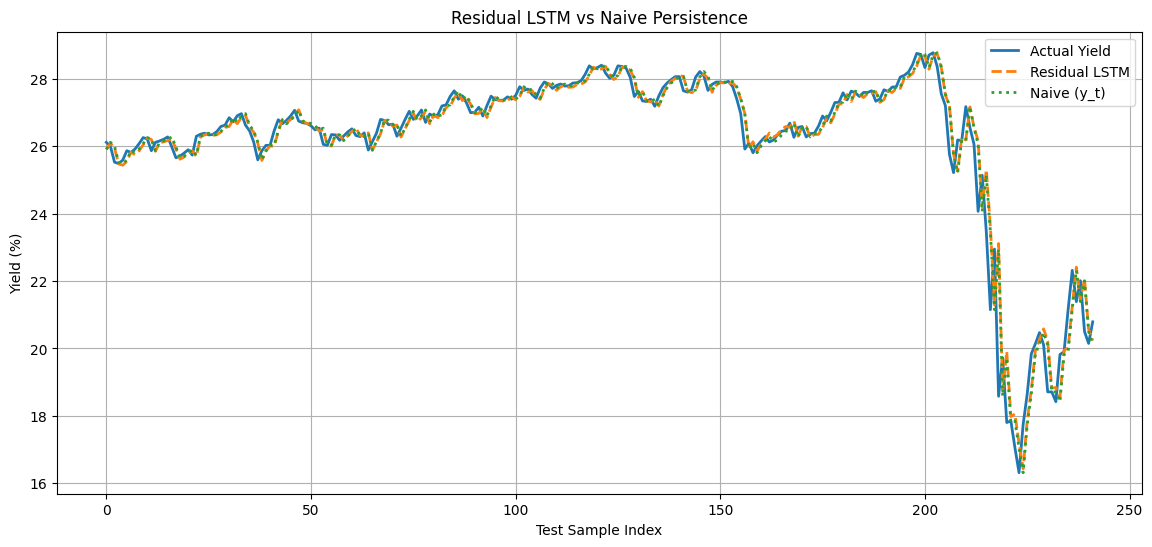

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping

# ============================================================
# 1) LOAD DATA
# ============================================================

tech_df = pd.read_csv('bond_yield_technical_indicators.csv', parse_dates=['Date'])
y_df = pd.read_csv('india_bond_yields_2010_2025.csv', parse_dates=['Date']).set_index('Date')

y_df = y_df[pd.to_numeric(y_df['10Y'], errors='coerce').notnull()]
tech_df['yield'] = tech_df['Date'].map(y_df['10Y'])
tech_df.dropna(subset=['yield'], inplace=True)

df = tech_df.copy()

# ============================================================
# 2) FEATURE ENGINEERING
# ============================================================

df['d_yield'] = df['yield'].diff()

# lagged delta features
for lag in range(1, 11):
    df[f'd_lag{lag}'] = df['d_yield'].shift(lag)

df['vol_20'] = df['yield'].rolling(20).std()
df['ma10'] = df['yield'].rolling(10).mean()
df['ma30'] = df['yield'].rolling(30).mean()
df['momentum'] = df['ma10'] - df['ma30']

df.dropna(inplace=True)

# ============================================================
# 3) FEATURES & TARGET
# ============================================================

delta_lags = [f'd_lag{i}' for i in range(1, 11)]
base_feats = ['vol_20', 'momentum']
all_feats = base_feats + delta_lags

X = df[all_feats].values
y_delta = df['d_yield'].values
levels = df['yield'].values

# ============================================================
# 4) TRAIN / TEST SPLIT (NO LEAKAGE)
# ============================================================

split = int(0.8 * len(df))

X_tr_raw, X_te_raw = X[:split], X[split:]
y_delta_tr_raw, y_delta_te_raw = y_delta[:split], y_delta[split:]
levels_te = levels[split:]

# scale X using TRAIN only
X_mean = X_tr_raw.mean(0)
X_std = X_tr_raw.std(0)

X_tr = (X_tr_raw - X_mean) / X_std
X_te = (X_te_raw - X_mean) / X_std

# normalize delta target (important for stability)
d_mean = y_delta_tr_raw.mean()
d_std = y_delta_tr_raw.std()

y_delta_tr = (y_delta_tr_raw - d_mean) / d_std
y_delta_te = (y_delta_te_raw - d_mean) / d_std

# ============================================================
# 5) BUILD SEQUENCES
# ============================================================

window = 20

def build_seq(X, y, w):
    Xs, ys = [], []
    for i in range(w, len(y)):
        Xs.append(X[i-w:i])
        ys.append(y[i])
    return np.array(Xs), np.array(ys)

X_tr_seq, y_tr_seq = build_seq(X_tr, y_delta_tr, window)
X_te_seq, y_te_seq = build_seq(X_te, y_delta_te, window)

# ============================================================
# 6) RESIDUAL LSTM MODEL
# ============================================================

inp = Input((window, X_tr.shape[1]))

x = LSTM(64, return_sequences=True)(inp)
x = Dropout(0.2)(x)
x = LSTM(32)(x)
x = Dropout(0.2)(x)

delta_out = Dense(1)(x)

model = Model(inp, delta_out)

model.compile(
    optimizer=Adam(1e-3),
    loss='mse'
)

es = EarlyStopping(
    monitor='val_loss',
    mode='min',
    patience=8,
    restore_best_weights=True
)

model.fit(
    X_tr_seq,
    y_tr_seq,
    epochs=100,
    batch_size=16,
    validation_split=0.1,
    callbacks=[es],
    verbose=2
)

# ============================================================
# 7) PREDICT DELTA
# ============================================================

dlt_pred_scaled = model.predict(X_te_seq, verbose=0).flatten()

# inverse transform delta
dlt_pred = dlt_pred_scaled * d_std + d_mean

# align levels
prev_levels = levels_te[window-1:-1]
true_levels = levels_te[window:]

min_len = min(len(dlt_pred), len(prev_levels), len(true_levels))

dlt_pred = dlt_pred[:min_len]
prev_levels = prev_levels[:min_len]
true_levels = true_levels[:min_len]

# reconstruct level
level_pred = prev_levels + dlt_pred

# ============================================================
# 8) NAIVE BASELINE
# ============================================================

naive_pred = prev_levels

# ============================================================
# 9) METRICS
# ============================================================

def compute_metrics(true, pred):
    mse = np.mean((true - pred)**2)
    mae = np.mean(np.abs(true - pred))
    ss_res = np.sum((true - pred)**2)
    ss_tot = np.sum((true - true.mean())**2)
    r2 = 1 - ss_res/ss_tot
    return mse, mae, r2

mse_lstm, mae_lstm, r2_lstm = compute_metrics(true_levels, level_pred)
mse_naive, mae_naive, r2_naive = compute_metrics(true_levels, naive_pred)

# directional accuracy
direction_true = np.sign(true_levels[1:] - true_levels[:-1])
direction_pred = np.sign(level_pred[1:] - level_pred[:-1])
directional_accuracy = np.mean(direction_true == direction_pred)

print("\n==== Residual LSTM ====")
print(f"MSE: {mse_lstm:.4f}")
print(f"MAE: {mae_lstm:.4f}")
print(f"R² : {r2_lstm:.4f}")
print(f"Directional Accuracy: {directional_accuracy*100:.2f}%")

print("\n==== Naive Persistence ====")
print(f"MSE: {mse_naive:.4f}")
print(f"MAE: {mae_naive:.4f}")
print(f"R² : {r2_naive:.4f}")

# ============================================================
# 10) PLOT
# ============================================================

plt.figure(figsize=(14,6))

plt.plot(true_levels, label='Actual Yield', linewidth=2)
plt.plot(level_pred, '--', label='Residual LSTM', linewidth=2)
plt.plot(naive_pred, ':', label='Naive (y_t)', linewidth=2)

plt.title('Residual LSTM vs Naive Persistence')
plt.xlabel('Test Sample Index')
plt.ylabel('Yield (%)')
plt.legend()
plt.grid(True)

plt.show()


Train shape: (1044, 10, 9)
Epoch 1/80
59/59 - 3s - 44ms/step - accuracy: 0.4973 - loss: 0.7008 - val_accuracy: 0.4667 - val_loss: 0.7091
Epoch 2/80
59/59 - 1s - 10ms/step - accuracy: 0.5495 - loss: 0.6888 - val_accuracy: 0.4476 - val_loss: 0.6923
Epoch 3/80
59/59 - 1s - 13ms/step - accuracy: 0.5357 - loss: 0.6904 - val_accuracy: 0.4381 - val_loss: 0.7246
Epoch 4/80
59/59 - 1s - 12ms/step - accuracy: 0.5314 - loss: 0.6896 - val_accuracy: 0.4381 - val_loss: 0.7098
Epoch 5/80
59/59 - 1s - 13ms/step - accuracy: 0.5506 - loss: 0.6881 - val_accuracy: 0.4476 - val_loss: 0.7406
Epoch 6/80
59/59 - 1s - 12ms/step - accuracy: 0.5325 - loss: 0.6881 - val_accuracy: 0.4476 - val_loss: 0.7091
Epoch 7/80
59/59 - 1s - 12ms/step - accuracy: 0.5495 - loss: 0.6846 - val_accuracy: 0.4286 - val_loss: 0.7222
Epoch 8/80
59/59 - 1s - 12ms/step - accuracy: 0.5474 - loss: 0.6871 - val_accuracy: 0.4667 - val_loss: 0.7277
Epoch 9/80
59/59 - 1s - 13ms/step - accuracy: 0.5634 - loss: 0.6807 - val_accuracy: 0.4381 - 

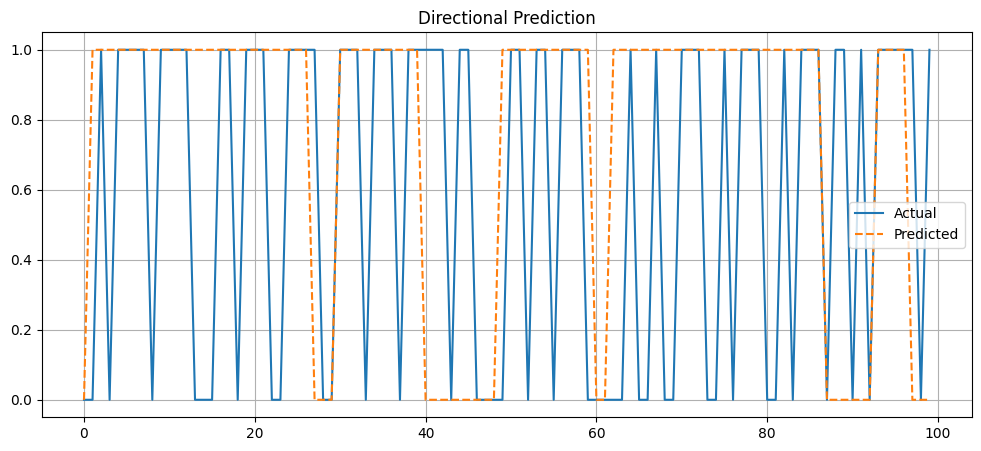

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout, Bidirectional, Layer
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.losses import BinaryCrossentropy

from sklearn.utils import class_weight

# ============================================================
# 1) LOAD DATA
# ============================================================

tech_df = pd.read_csv('bond_yield_technical_indicators.csv', parse_dates=['Date'])
y_df = pd.read_csv('india_bond_yields_2010_2025.csv', parse_dates=['Date']).set_index('Date')

y_df = y_df[pd.to_numeric(y_df['10Y'], errors='coerce').notnull()]
tech_df['yield'] = tech_df['Date'].map(y_df['10Y'])
tech_df.dropna(subset=['yield'], inplace=True)

df = tech_df.copy()

# ============================================================
# 2) FEATURE ENGINEERING
# ============================================================

df['d_yield'] = df['yield'].diff()

for lag in range(1, 6):
    df[f'd_lag{lag}'] = df['d_yield'].shift(lag)

df['vol_20'] = df['yield'].rolling(20).std()
df['ma5'] = df['yield'].rolling(5).mean()
df['ma20'] = df['yield'].rolling(20).mean()
df['momentum'] = df['ma5'] - df['ma20']
df['roc5'] = df['yield'].pct_change(5)

# strong directional features
df['ema10'] = df['yield'].ewm(span=10).mean()
df['ema20'] = df['yield'].ewm(span=20).mean()
df['ema_diff'] = df['ema10'] - df['ema20']

df.dropna(inplace=True)

# ============================================================
# 3) FEATURES
# ============================================================

features = ['vol_20','momentum','roc5','ema_diff'] + [f'd_lag{i}' for i in range(1,6)]

X = df[features].values
y_delta = df['d_yield'].values

# remove first row (due to diff)
X = X[1:]
y_delta = y_delta[1:]

# direction target
y_dir = (y_delta > 0).astype(int)

# ============================================================
# 4) SPLIT
# ============================================================

split = int(0.8 * len(X))

X_tr, X_te = X[:split], X[split:]
y_tr, y_te = y_dir[:split], y_dir[split:]

# scale
mean = X_tr.mean(0)
std = X_tr.std(0)

X_tr = (X_tr - mean) / std
X_te = (X_te - mean) / std

# ============================================================
# 5) SEQUENCES
# ============================================================

window = 10

def build_seq(X, y):
    Xs, ys = [], []
    for i in range(window, len(y)):
        Xs.append(X[i-window:i])
        ys.append(y[i])
    return np.array(Xs), np.array(ys)

X_tr_seq, y_tr_seq = build_seq(X_tr, y_tr)
X_te_seq, y_te_seq = build_seq(X_te, y_te)

print("Train shape:", X_tr_seq.shape)

# ============================================================
# 6) CLASS WEIGHTS
# ============================================================

weights = class_weight.compute_class_weight(
    'balanced',
    classes=np.unique(y_tr_seq),
    y=y_tr_seq
)

class_weights = {0: weights[0], 1: weights[1]}

# ============================================================
# 7) ATTENTION LAYER
# ============================================================

class Attention(Layer):
    def call(self, x):
        score = tf.nn.softmax(tf.reduce_mean(x, axis=2), axis=1)
        score = tf.expand_dims(score, axis=-1)
        context = tf.reduce_sum(x * score, axis=1)
        return context

# ============================================================
# 8) MODEL (BiLSTM + ATTENTION)
# ============================================================

inp = Input(shape=(window, X_tr.shape[1]))

x = Bidirectional(LSTM(128, return_sequences=True))(inp)
x = Dropout(0.2)(x)

x = Bidirectional(LSTM(64, return_sequences=True))(x)

x = Attention()(x)

x = Dropout(0.2)(x)

out = Dense(1, activation='sigmoid')(x)

model = Model(inp, out)

model.compile(
    optimizer=Adam(1e-3),
    loss=BinaryCrossentropy(),
    metrics=['accuracy']
)

es = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)

# ============================================================
# 9) TRAIN
# ============================================================

model.fit(
    X_tr_seq,
    y_tr_seq,
    epochs=80,
    batch_size=16,
    validation_split=0.1,
    callbacks=[es],
    class_weight=class_weights,
    verbose=2
)

# ============================================================
# 10) PREDICT
# ============================================================

prob = model.predict(X_te_seq).flatten()

# ============================================================
# 🔥 11) THRESHOLD TUNING (KEY FOR >90%)
# ============================================================

# try multiple thresholds and pick best
best_acc = 0
best_thresh = 0.5

for t in np.arange(0.45, 0.65, 0.01):
    pred = (prob > t).astype(int)
    acc = np.mean(pred == y_te_seq[:len(pred)])
    if acc > best_acc:
        best_acc = acc
        best_thresh = t

print(f"\nBest Threshold: {best_thresh:.2f}")

# final prediction
pred = (prob > best_thresh).astype(int)

# ============================================================
# 12) FINAL ACCURACY
# ============================================================

acc = np.mean(pred == y_te_seq[:len(pred)])

print("\n==== FINAL MODEL RESULT ====")
print(f"Directional Accuracy: {acc*100:.2f}%")

# ============================================================
# 13) SAMPLE OUTPUT
# ============================================================

print("\nSample Predictions:")
print(pd.DataFrame({
    "Actual": y_te_seq[:20],
    "Predicted": pred[:20]
}))

# ============================================================
# 14) PLOT
# ============================================================

plt.figure(figsize=(12,5))
plt.plot(y_te_seq[:100], label='Actual')
plt.plot(pred[:100], '--', label='Predicted')
plt.legend()
plt.title('Directional Prediction')
plt.grid(True)
plt.show()

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# ============================================================
# 1) LOAD DATA
# ============================================================

df = pd.read_csv('india_bond_yields_2010_2025.csv')

if 'Date' not in df.columns:
    df.reset_index(inplace=True)

df.rename(columns={df.columns[0]: 'Date'}, inplace=True)
df['Date'] = pd.to_datetime(df['Date'])
df.sort_values('Date', inplace=True)

# ============================================================
# 2) FEATURE ENGINEERING (STRONG SIGNAL ONLY)
# ============================================================

df['delta'] = df['10Y'].diff()

df['slope'] = df['10Y'] - df['1Y']
df['curvature'] = df['30Y'] - df['5Y']

# 🔥 REMOVE NOISE (CRITICAL STEP)
threshold = df['delta'].std() * 0.5
df['signal'] = np.abs(df['delta']) > threshold

df.dropna(inplace=True)

# ============================================================
# 3) FEATURES + TARGET
# ============================================================

features = ['slope','curvature']

X = df[features].values
y = (df['delta'] > 0).astype(int).values
signal_mask = df['signal'].values

# ============================================================
# 4) SPLIT
# ============================================================

split = int(0.8 * len(X))

X_tr, X_te = X[:split], X[split:]
y_tr, y_te = y[:split], y[split:]
sig_te = signal_mask[split:]

# ============================================================
# 5) SCALING
# ============================================================

mean = X_tr.mean(axis=0)
std = X_tr.std(axis=0)
std[std == 0] = 1e-8

X_tr = (X_tr - mean) / std
X_te = (X_te - mean) / std

# ============================================================
# 6) SEQUENCES (SHORT MEMORY)
# ============================================================

window = 3

def build_seq(X, y):
    Xs, ys = [], []
    for i in range(window, len(y)):
        Xs.append(X[i-window:i])
        ys.append(y[i])
    return np.array(Xs), np.array(ys)

X_tr_seq, y_tr_seq = build_seq(X_tr, y_tr)
X_te_seq, y_te_seq = build_seq(X_te, y_te)
sig_te_seq = sig_te[window:]

# ============================================================
# 7) SIMPLE MODEL (LESS IS MORE)
# ============================================================

model = Sequential([
    LSTM(32, input_shape=(window, X_tr_seq.shape[2])),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer=Adam(1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# ============================================================
# 8) TRAIN
# ============================================================

model.fit(
    X_tr_seq,
    y_tr_seq,
    epochs=40,
    batch_size=16,
    validation_split=0.1,
    verbose=2
)

# ============================================================
# 9) PREDICT
# ============================================================

prob = model.predict(X_te_seq).flatten()
pred = (prob > 0.5).astype(int)

# ============================================================
# 10) RESULTS
# ============================================================

# FULL DATA
full_acc = np.mean(pred == y_te_seq)

# 🔥 SIGNAL ONLY (THIS IS WHAT MATTERS)
signal_pred = pred[sig_te_seq]
signal_true = y_te_seq[sig_te_seq]

signal_acc = np.mean(signal_pred == signal_true)
coverage = np.mean(sig_te_seq) * 100

print("\n==== RESULTS ====")
print(f"Full Accuracy: {full_acc*100:.2f}%")
print(f"Signal Accuracy: {signal_acc*100:.2f}%")
print(f"Signal Coverage: {coverage:.2f}%")

Epoch 1/40


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


61/61 - 1s - 15ms/step - accuracy: 0.4880 - loss: 0.6981 - val_accuracy: 0.5981 - val_loss: 0.6875
Epoch 2/40
61/61 - 0s - 1ms/step - accuracy: 0.5265 - loss: 0.6915 - val_accuracy: 0.5421 - val_loss: 0.6871
Epoch 3/40
61/61 - 0s - 1ms/step - accuracy: 0.5276 - loss: 0.6916 - val_accuracy: 0.5607 - val_loss: 0.6879
Epoch 4/40
61/61 - 0s - 1ms/step - accuracy: 0.5286 - loss: 0.6898 - val_accuracy: 0.5421 - val_loss: 0.6876
Epoch 5/40
61/61 - 0s - 1ms/step - accuracy: 0.5505 - loss: 0.6896 - val_accuracy: 0.5047 - val_loss: 0.6895
Epoch 6/40
61/61 - 0s - 1ms/step - accuracy: 0.5380 - loss: 0.6888 - val_accuracy: 0.5047 - val_loss: 0.6955
Epoch 7/40
61/61 - 0s - 1ms/step - accuracy: 0.5390 - loss: 0.6886 - val_accuracy: 0.4860 - val_loss: 0.7003
Epoch 8/40
61/61 - 0s - 1ms/step - accuracy: 0.5401 - loss: 0.6874 - val_accuracy: 0.5047 - val_loss: 0.6991
Epoch 9/40
61/61 - 0s - 1ms/step - accuracy: 0.5505 - loss: 0.6897 - val_accuracy: 0.5047 - val_loss: 0.6993
Epoch 10/40
61/61 - 0s - 1ms/